<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/HQNN_SWAPAttackSQUASH_Kumar2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SQUASH: a SWAP-based circuit attack on a hybrid quantum neural network (Kumar et al., 2025) step by step

This notebook re-implements, runs and checks the attack of

> Rahul Kumar, Wenqi Wei, Ying Mao, Junaid Farooq, Ying Wang and Juntao Chen,
> "SQUASH: A SWAP-Based Quantum Attack to Sabotage Hybrid Quantum Neural Networks",
> arXiv:2506.24081 [quant-ph], 30 June 2025, https://arxiv.org/abs/2506.24081.

The authors publish no code, so everything below is written from the six-page paper.

**What the notebook does.**
1. Downloads the real images the paper uses: MNIST (digits 0/1 and all ten digits) and CIFAR-10 (cat/dog and all ten classes).
2. Builds the victim, a *hybrid quantum neural network* (HQNN): two convolutional layers, dropout and two fully connected layers
   squeeze each image into **two angles**; a **2-qubit variational circuit plus a SWAP test** (ancilla, Hadamard, controlled-SWAP,
   Hadamard) turns the angles into quantum readouts and a "fidelity"; a small fully connected head turns the readouts into class scores.
   The circuit is simulated exactly with PennyLane and cross-checked gate by gate against an independent Qiskit statevector simulation.
3. Trains the clean model, with the same seeds, on the four tasks (MNIST-2, CIFAR-2, MNIST-10, CIFAR-10) and trains classical
   baselines on identical inputs (a random forest and an RBF-SVM on PCA pixels, and the same CNN with the quantum layer replaced by a
   classical layer).
4. Mounts **SQUASH**: an *untargeted* attack (1, 2 or 3 randomly placed SWAP gates inside the variational circuit, over many random
   draws) and a *targeted* attack (at most two SWAP gates chosen by the attacker from black-box queries to hit one class).
5. Re-draws the paper's tables (clean vs untargeted, Table I; clean vs targeted, Table II), measures the SWAP overhead (CNOT count and
   run time) and prints per claim whether it is reproduced.

**How to run.** Colab, CPU runtime, *Runtime > Run all*. `FAST_MODE = True` (class demo, small samples) takes about 5-10 minutes; `FAST_MODE =
False` uses the larger budgets documented in the configuration cell (about 45 minutes). No GPU, no IBM account and no token is needed. The data are
fetched from the public Hugging Face mirrors `ylecun/mnist` and `uoft-cs/cifar10`; if your Hugging Face session needs a token, put it in
Colab *Secrets* under the name `HF_TOKEN` (the notebook reads it from there or from the environment variable `HF_TOKEN` and never prints it).

**What you get at the end.** The accuracy and negative log-likelihood of the clean and of the sabotaged HQNN, the per-class damage of the
targeted attack, the circuit diagrams of the clean and attacked circuits, an overhead measurement, a table of paper-versus-notebook numbers
with a verdict per claim, and a critical reading of the paper.

## The paper in one page

**Problem.** Open-source HQNN code is downloaded and trusted. The paper asks what happens if an attacker changes the *circuit structure*
(not the data, not the weights) by inserting SWAP gates into the variational quantum circuit.

**Threat model (Fig. 1).** A user downloads an HQNN repository from GitHub. A malicious configuration file shipped with it injects SWAP
gate(s) into the circuit when training/execution is started. The attacker needs no training data and does not touch the inputs, so the
attack is "stealthy" at the data level.

**Victim (Section IV-C).** Two convolutional layers + dropout, flatten, two fully connected layers whose last output has **2 values**,
a **2-qubit** quantum layer (feature map, variational ansatz), a **SWAP test** on a pair of qubits as measurement layer (ancilla, H,
CSWAP, H; `P(0) = (1 + |<psi|phi>|^2)/2`), and a final fully connected layer that maps qubit outputs and fidelities to the classes.
Qiskit simulation with a PyTorch wrapper; negative log-likelihood (NLL) and accuracy are reported.

**Data (Section V-A).** MNIST-2 (digits 0 and 1), CIFAR-2 (cat and dog), MNIST-10, CIFAR-10, class-balanced splits.

**Attacks (Section IV-B, Algorithm 1).**
* *Untargeted*: random SWAP gates between circuit qubits, ancilla included, to disturb the fidelity measurements of all classes.
* *Targeted*: make `F(psi_t, chi) > F(psi_c, chi)` for an adversary-chosen target class `t`, using two SWAP tests; only the target class
  should suffer, so that overall accuracy still looks acceptable.

**Claims to check.**
1. Clean accuracy (Table I): MNIST-2 96.01 %, CIFAR-2 90.78 %, MNIST-10 93.11 %, CIFAR-10 77.42 % (one SWAP test).
2. Untargeted SWAP attack (Table I, 1/2/3 SWAP tests): MNIST-2 43.91 / 35.22 / 21.78 %, CIFAR-2 38.04 / 30.92 / 18.12 %,
   MNIST-10 38.27 / 32.64 / 19.31 %, CIFAR-10 34.07 / 27.18 / 15.84 %; NLL rises; "up to 74.08 %" accuracy reduction.
3. Targeted SWAP attack (Table II): target-class accuracy 19.14 / 18.12 / 20.94 / 15.84 %, total accuracy 57.075 / 54.062 / 85.164 / 73.919 %
   on MNIST-2 / CIFAR-2 / MNIST-10 / CIFAR-10; "up to 79.78 %" reduction of the target class.
4. Overhead (Fig. 5): +5.96 % run time per epoch for the targeted attack and +16.05 % for the untargeted one (SWAP = 3 CNOT).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | Qiskit + custom PyTorch wrapper | PennyLane 0.45.1 `default.qubit` (exact, differentiable, PyTorch interface) for training and attacks; every circuit is also built in Qiskit 2.5.2 and the expectation values are asserted equal |
| Data | MNIST-2 (0/1), CIFAR-2 (cat/dog), MNIST-10, CIFAR-10; class-balanced | same classes, real images from the Hugging Face mirrors; `# CHOICE:` class-balanced random subsets (sizes in the configuration cell), because simulating a quantum layer for every image is slow |
| Test data | not stated | `# CHOICE:` the official test set, split 80/20 into an evaluation set and an *attacker probe* set (never used for training or tuning) |
| Classical front end | 2 conv layers, dropout, 2 FC layers, 2-d output | `# CHOICE:` 2x2 average pooling of the image (CPU budget), Conv(8,3x3)-ReLU-pool, Conv(16,3x3)-ReLU-pool, dropout 0.25, FC 32, FC 2; angles `pi*tanh(.)` |
| Feature map | "feature map layer", 2 qubits | `# CHOICE:` Qiskit `zz_feature_map(2, reps=1)` written as an explicit gate list (H, P(2x), CX, P(2(pi-x0)(pi-x1)), CX) |
| Ansatz | "variational ansatz of parameterised blocks" | `# CHOICE:` `efficient_su2(2, reps=2)` layout: 3 rotation layers (RY, RZ) separated by 2 CNOTs, **12 parameters** |
| Measurement | SWAP test on a pair of qubits; qubit outputs and fidelities go to an FC layer | `# CHOICE:` ancilla = qubit 0, SWAP test on qubits (1, 2); readouts `<Z1>`, `<Z2>` (circuit without the test) and `P(0) = (1 + <SWAP>)/2` (circuit with the test) |
| Final layer | FC layer | `# CHOICE:` FC(3,32)-ReLU-FC(32,classes) |
| Optimiser, epochs | not stated ("100 training iterations") | `# CHOICE:` Adam, learning rate 3e-3, batch 64, epochs in the configuration cell |
| When the attack acts | "after the user initiated training execution" | `# CHOICE:` primary experiment: SWAPs are inserted into the trained victim at inference (weights fixed). A second experiment retrains the model with the SWAPs already in the circuit |
| Clean model for k = 1, 2, 3 | one clean row per SWAP count | `# CHOICE:` one clean model per dataset and seed (the number of malicious SWAPs k only changes the attacked columns) |
| "Random SWAP gates between circuit qubits" | position and qubits not specified | `# CHOICE:` each SWAP gets a uniformly random slot (after the feature map, after the first or after the last ansatz layer) and a random qubit pair among (0,1), (0,2), (1,2) (ancilla included); 30 random draws per k |
| Untargeted variant with SWAP *tests* | text says "SWAP tests" | also evaluated: each malicious unit is H - CSWAP - H on a random (control, pair) |
| Targeted attack (Algorithm 1) | gradient search on an input phase `delta` until `F_t > F_c` | `# CHOICE:` Algorithm 1 is under-specified for a circuit-only attack. The attacker queries the victim as a black box on unlabeled probe images, pseudo-labels them with the victim's own answers and searches **all** sequences of at most two SWAP gates (90 candidates) for the one that destroys the target class most while keeping the other classes. No gradients, no training data |
| Overhead | wall time per epoch | CNOT count after Qiskit transpilation and measured inference time of the simulated quantum layer (a simulator overhead, not an epoch time) |
| Seeds | "fixed random seed" | `SEED = 42`; mean +- std over the seeds listed in the configuration cell |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "qiskit", "torch", "pyarrow", "huggingface_hub", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" pylatexenc pyarrow huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages already present; skipping pip install.")

All packages already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant is here ----------------
FAST_MODE = False            # True: class demo, a few minutes. False: the larger budgets below (see the runtime note in the text).
SEED      = 42              # CHOICE: the paper only says "a fixed random seed"
IBM_TOKEN = ""              # not used: nothing here needs real hardware (the paper simulates the circuit as well)
DATA_DIR  = "data"          # cache for the downloaded images (a few tens of MB; the 120 MB CIFAR parquet is deleted after reading)

TORCH_THREADS = 1           # the networks are tiny: one thread is faster than several (thread synchronisation dominates, especially on a shared CPU)
N_QUBITS_DATA = 2           # paper: 2-qubit quantum layer (+ 1 ancilla for the SWAP test)
LR, BATCH, VAL_FRAC = 3e-3, 64, 0.10        # CHOICE: Adam (tuned once on MNIST-10 validation data: 3e-3/64 beat 5e-3/128); 10 % of the training subset is held out only to monitor training

if FAST_MODE:
    SEEDS   = [SEED]
    A_DRAWS = 10            # random placements per number of malicious SWAPs (untargeted attack)
    # name: (original class ids, train images, test-pool images per class, epochs)
    SPEC = {"MNIST-2":  ((0, 1),            1500, 400, 6),
            "CIFAR-2":  ((3, 5),            2400, 400, 8),
            "MNIST-10": (tuple(range(10)),  3000, 120, 10),
            "CIFAR-10": (tuple(range(10)),  3000, 120, 10)}
    RETRAIN_SETS = ["MNIST-2"]               # datasets for the "attack present during training" experiment
else:
    # Full budgets (three seeds, larger subsets, 30 random draws per k, attack-during-training experiment on two tasks).
    # Measured on a shared 4-core laptop CPU (torch limited to one thread): about 45 minutes in total, 35 of them training (FAST_MODE: about 5 minutes).
    SEEDS   = [SEED, SEED + 1, SEED + 2]
    A_DRAWS = 30
    SPEC = {"MNIST-2":  ((0, 1),            6000,  980, 8),
            "CIFAR-2":  ((3, 5),            10000, 1000, 14),
            "MNIST-10": (tuple(range(10)),  12000, 300, 14),
            "CIFAR-10": (tuple(range(10)),  13000, 250, 14)}
    RETRAIN_SETS = ["MNIST-2", "MNIST-10"]
PROBE_FRAC = 0.20           # share of the official test images given to the attacker as unlabeled probe queries (the rest is the evaluation set)
K_LIST     = (1, 2, 3)      # number of malicious SWAPs in the untargeted attack (paper: 1, 2, 3)
SHOTS      = None           # exact expectation values (analytic simulation); the paper does not state shots
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| datasets", list(SPEC))

FAST_MODE = False | seeds [42, 43, 44] | datasets ['MNIST-2', 'CIFAR-2', 'MNIST-10', 'CIFAR-10']


In [3]:
import os, io, time, json, itertools, warnings, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split
import pennylane as qml
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp

# --- Hugging Face token: only from the environment or Colab Secrets, never printed, never written to a file ---
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.set_num_threads(TORCH_THREADS)
def set_seeds(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seeds(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .25})
print("torch", torch.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The data: MNIST and CIFAR-10

The paper uses four tasks: **MNIST-2** (digits 0 and 1), **CIFAR-2** (cat and dog), **MNIST-10** and **CIFAR-10** (all ten classes).
The images come from the public Hugging Face parquet mirrors (`ylecun/mnist`, `uoft-cs/cifar10`). The CIFAR training parquet is 120 MB;
the code reads it once, keeps a class-balanced subset as a compressed `.npz` of a few tens of MB and **deletes the parquet** again.
For every task the notebook draws a class-balanced training subset from the official training set and a class-balanced pool from the
official test set. The pool is split 80/20 (stratified) into an **evaluation set** and an **attacker probe set**; the probe images are only
ever used as unlabeled queries by the targeted attack.

In [4]:
CIFAR_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MNIST_NAMES = [str(i) for i in range(10)]

def _hf_file(repo, fname):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id=repo, repo_type="dataset", filename=fname, local_dir=os.path.join(DATA_DIR, "hf_tmp"),
                           token=HF_TOKEN if HF_TOKEN else None)

def _decode(series):
    from PIL import Image
    return np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in series])

def _balanced(labels, classes, per_class, rng_):
    idx = []
    for c in classes:
        ids = np.flatnonzero(labels == c); rng_.shuffle(ids); idx.append(ids[:per_class])
    idx = np.concatenate(idx); rng_.shuffle(idx); return idx

def _build_cache(kind):
    """Download the parquet files, keep the class-balanced subsets used by the FULL configuration, delete the parquet files."""
    r = np.random.default_rng(12345)
    full = {"MNIST-2": ((0, 1), 6000, 980), "MNIST-10": (tuple(range(10)), 12000, 300),
            "CIFAR-2": ((3, 5), 10000, 1000), "CIFAR-10": (tuple(range(10)), 13000, 250)}
    names = [n for n in full if n.startswith(kind)]
    if kind == "MNIST":
        repo, tr_f, te_f, col = "ylecun/mnist", "mnist/train-00000-of-00001.parquet", "mnist/test-00000-of-00001.parquet", "image"
    else:
        repo, tr_f, te_f, col = "uoft-cs/cifar10", "plain_text/train-00000-of-00001.parquet", "plain_text/test-00000-of-00001.parquet", "img"
    files = []
    try:
        p_tr, p_te = _hf_file(repo, tr_f), _hf_file(repo, te_f); files = [p_tr, p_te]
        df_tr, df_te = pd.read_parquet(p_tr), pd.read_parquet(p_te)
    except Exception as e:
        if kind != "MNIST": raise
        print("Hugging Face download failed (%s); falling back to the Keras mnist.npz" % type(e).__name__)
        import requests
        url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
        d = np.load(io.BytesIO(requests.get(url, timeout=300).content))
        df_tr = pd.DataFrame({"label": d["y_train"], "image": list(d["x_train"])}); df_te = pd.DataFrame({"label": d["y_test"], "image": list(d["x_test"])})
    ytr, yte = df_tr["label"].to_numpy(), df_te["label"].to_numpy()
    dec = (lambda s: _decode(s)) if isinstance(df_tr[col].iloc[0], dict) else (lambda s: np.stack(list(s)))
    for name in names:
        classes, n_train, pool_pc = full[name]
        i_tr = _balanced(ytr, classes, n_train // len(classes), r)
        i_te = _balanced(yte, classes, pool_pc, r)
        xtr, xte = dec(df_tr[col].iloc[i_tr]), dec(df_te[col].iloc[i_te])
        np.savez_compressed(os.path.join(DATA_DIR, f"{name}.npz"), x_train=xtr.astype(np.uint8), y_train=ytr[i_tr],
                            x_pool=xte.astype(np.uint8), y_pool=yte[i_te])
        print(f"cached {name}: train {xtr.shape}, pool {xte.shape}")
    del df_tr, df_te
    for f in files:                                   # delete the downloaded parquet files (the CIFAR training file is 120 MB)
        try: os.remove(f)
        except OSError: pass

def ensure_cache():
    for kind in ("MNIST", "CIFAR"):
        if not all(os.path.exists(os.path.join(DATA_DIR, f"{n}.npz")) for n in SPEC if n.startswith(kind)):
            t0 = time.time(); _build_cache(kind); print(f"{kind} cache built in {time.time() - t0:.0f} s")
ensure_cache()

def load_task(name):
    """Return a dict with float32 images in [0,1] (N,C,H,W), integer labels, split in train / probe / test (FAST or FULL sizes)."""
    classes, n_train, pool_pc, _ = SPEC[name]
    d = np.load(os.path.join(DATA_DIR, f"{name}.npz"))
    xt, yt, xp, yp = d["x_train"], d["y_train"], d["x_pool"], d["y_pool"]
    r = np.random.default_rng(SEED)
    def take(y, per_class):                                    # first `per_class` of every class (the cached order is already random)
        return np.concatenate([np.flatnonzero(y == c)[:per_class] for c in classes])
    i_tr = take(yt, n_train // len(classes)); i_po = take(yp, pool_pc)
    r.shuffle(i_tr)
    x_tr, y_tr, x_po, y_po = xt[i_tr], yt[i_tr], xp[i_po], yp[i_po]
    cmap = {c: k for k, c in enumerate(classes)}                    # original label -> 0..C-1
    prep = lambda x: (x[:, None] if x.ndim == 3 else x.transpose(0, 3, 1, 2)).astype(np.float32) / 255.0
    y_tr_m, y_po_m = np.array([cmap[c] for c in y_tr]), np.array([cmap[c] for c in y_po])
    i_ev, i_pr = train_test_split(np.arange(len(y_po_m)), test_size=PROBE_FRAC, stratify=y_po_m, random_state=SEED)
    names = MNIST_NAMES if name.startswith("MNIST") else CIFAR_NAMES
    return dict(name=name, classes=classes, class_names=[names[c] for c in classes], n_classes=len(classes),
                x_train=prep(x_tr), y_train=y_tr_m, y_train_orig=y_tr,
                x_probe=prep(x_po[i_pr]), y_probe=y_po_m[i_pr], x_test=prep(x_po[i_ev]), y_test=y_po_m[i_ev],
                n_feat=int(np.prod(x_tr.shape[1:])))

TASKS = {n: load_task(n) for n in SPEC}
for n, t in TASKS.items():
    print(f"{n:9s} train {t['x_train'].shape}  probe {t['x_probe'].shape}  test {t['x_test'].shape}  classes {t['class_names']}")

MNIST-2   train (6000, 1, 28, 28)  probe (392, 1, 28, 28)  test (1568, 1, 28, 28)  classes ['0', '1']
CIFAR-2   train (10000, 3, 32, 32)  probe (400, 3, 32, 32)  test (1600, 3, 32, 32)  classes ['cat', 'dog']
MNIST-10  train (12000, 1, 28, 28)  probe (600, 1, 28, 28)  test (2400, 1, 28, 28)  classes ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
CIFAR-10  train (13000, 3, 32, 32)  probe (500, 3, 32, 32)  test (2000, 3, 32, 32)  classes ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Dataset Exploration and Visualisation

Everything in this section is computed from the real images the experiments use. For every task the cells print the shape, the feature
names (raw pixel intensities, row by row and channel by channel), the original label values and the class counts, draw the class
distribution, a gallery of real images and a **2-D scatter plot in which every point is a real image coloured by its ground-truth label**:
first the raw PCA coordinates (PCA fitted on the training split only), then the same coordinates scaled to [0, pi] (the range of the
rotation angles that the quantum layer receives; the scaler is fitted on the training split, test points are clipped). Ten-class tasks keep
all ten labels. Nothing is simulated or invented.

In [5]:
### Shape, feature names, original labels, class counts
rows = []
for n, t in TASKS.items():
    h, w = t["x_train"].shape[2:]; c = t["x_train"].shape[1]
    print(f"[{n}] train images {t['x_train'].shape} (N, channels, height, width) -> flattened feature matrix ({len(t['x_train'])}, {t['n_feat']})")
    print(f"      feature names: p0 ... p{t['n_feat'] - 1} (pixel intensities in [0,1]; {c} channel(s) x {h} x {w}); first five: {[f'p{i}' for i in range(5)]}")
    print(f"      original label values (dataset ids): {list(t['classes'])} -> names {t['class_names']}")
    for split in ("train", "probe", "test"):
        cnt = np.bincount(t["y_" + split], minlength=t["n_classes"])
        rows.append(dict(task=n, split=split, **{cn: int(k) for cn, k in zip(t["class_names"], cnt)}))
    print()
display(pd.DataFrame(rows).set_index(["task", "split"]).fillna(""))

[MNIST-2] train images (6000, 1, 28, 28) (N, channels, height, width) -> flattened feature matrix (6000, 784)
      feature names: p0 ... p783 (pixel intensities in [0,1]; 1 channel(s) x 28 x 28); first five: ['p0', 'p1', 'p2', 'p3', 'p4']
      original label values (dataset ids): [0, 1] -> names ['0', '1']

[CIFAR-2] train images (10000, 3, 32, 32) (N, channels, height, width) -> flattened feature matrix (10000, 3072)
      feature names: p0 ... p3071 (pixel intensities in [0,1]; 3 channel(s) x 32 x 32); first five: ['p0', 'p1', 'p2', 'p3', 'p4']
      original label values (dataset ids): [3, 5] -> names ['cat', 'dog']

[MNIST-10] train images (12000, 1, 28, 28) (N, channels, height, width) -> flattened feature matrix (12000, 784)
      feature names: p0 ... p783 (pixel intensities in [0,1]; 1 channel(s) x 28 x 28); first five: ['p0', 'p1', 'p2', 'p3', 'p4']
      original label values (dataset ids): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> names ['0', '1', '2', '3', '4', '5', '6', '7', '8'

0       1     cat     dog       2       3       4       5       6       7       8       9 airplane automobile    bird    deer    frog   horse    ship   truck
task     split                                                                                                                                                                    
MNIST-2  train  3000.0  3000.0                                                                                                                                                    
         probe   196.0   196.0                                                                                                                                                    
         test    784.0   784.0                                                                                                                                                    
CIFAR-2  train                  5000.0  5000.0                                                                                                                                    
         probe                   200.0   200.0                                                                                                                                    
         test                    800.0   800.0                                                                                                                                    
MNIST-10 train  1200.0  1200.0                  1200.0  1200.0  1200.0  1200.0  1200.0  1200.0  1200.0  1200.0                                                                    
         probe    60.0    60.0                    60.0    60.0    60.0    60.0    60.0    60.0    60.0    60.0                                                                    
         test    240.0   240.0                   240.0   240.0   240.0   240.0   240.0   240.0   240.0   240.0                                                                    
CIFAR-10 train                  1300.0  1300.0                                                                   1300.0     1300.0  1300.0  1300.0  1300.0  1300.0  1300.0  1300.0
         probe                    50.0    50.0                                                                     50.0       50.0    50.0    50.0    50.0    50.0    50.0    50.0
         test                    200.0   200.0                                                                    200.0      200.0   200.0   200.0   200.0   200.0   200.0   200.0

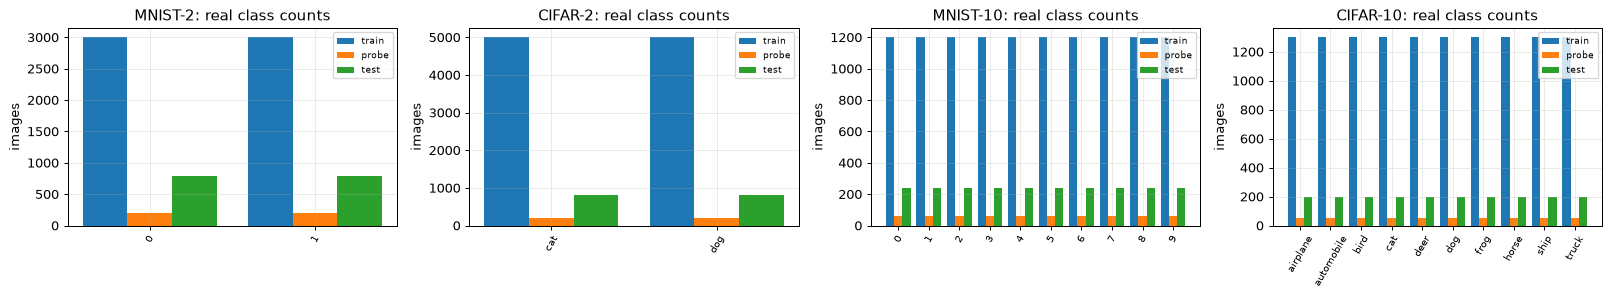

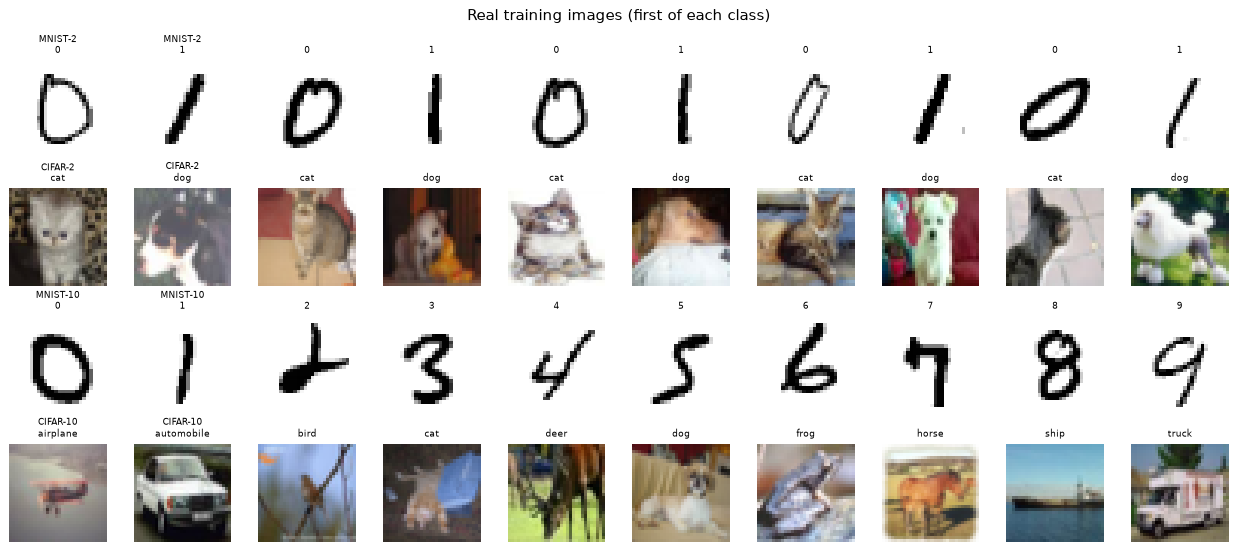

In [6]:
### Class distribution of the real data (bar charts) and a gallery of real images
fig, axs = plt.subplots(1, 4, figsize=(18, 3.4))
for ax, (n, t) in zip(axs, TASKS.items()):
    w = 0.27
    for k, split in enumerate(("train", "probe", "test")):
        cnt = np.bincount(t["y_" + split], minlength=t["n_classes"]); ax.bar(np.arange(t["n_classes"]) + (k - 1) * w, cnt, w, label=split)
    ax.set_xticks(range(t["n_classes"])); ax.set_xticklabels(t["class_names"], rotation=60, fontsize=8); ax.set_title(f"{n}: real class counts"); ax.set_ylabel("images")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(4, 10, figsize=(14, 6.2))
for r_, (n, t) in enumerate(TASKS.items()):
    for k in range(10):
        ax = axs[r_, k]; ax.axis("off")
        c = k % t["n_classes"]
        if k < t["n_classes"] or t["n_classes"] == 2:
            ids = np.flatnonzero(t["y_train"] == c)
            img = t["x_train"][ids[k // t["n_classes"]]]
            ax.imshow(img[0] if img.shape[0] == 1 else img.transpose(1, 2, 0), cmap="gray_r" if img.shape[0] == 1 else None)
            ax.set_title(f"{n}\n{t['class_names'][c]}" if k < 2 else t["class_names"][c], fontsize=7)
plt.suptitle("Real training images (first of each class)"); plt.tight_layout(); plt.show()

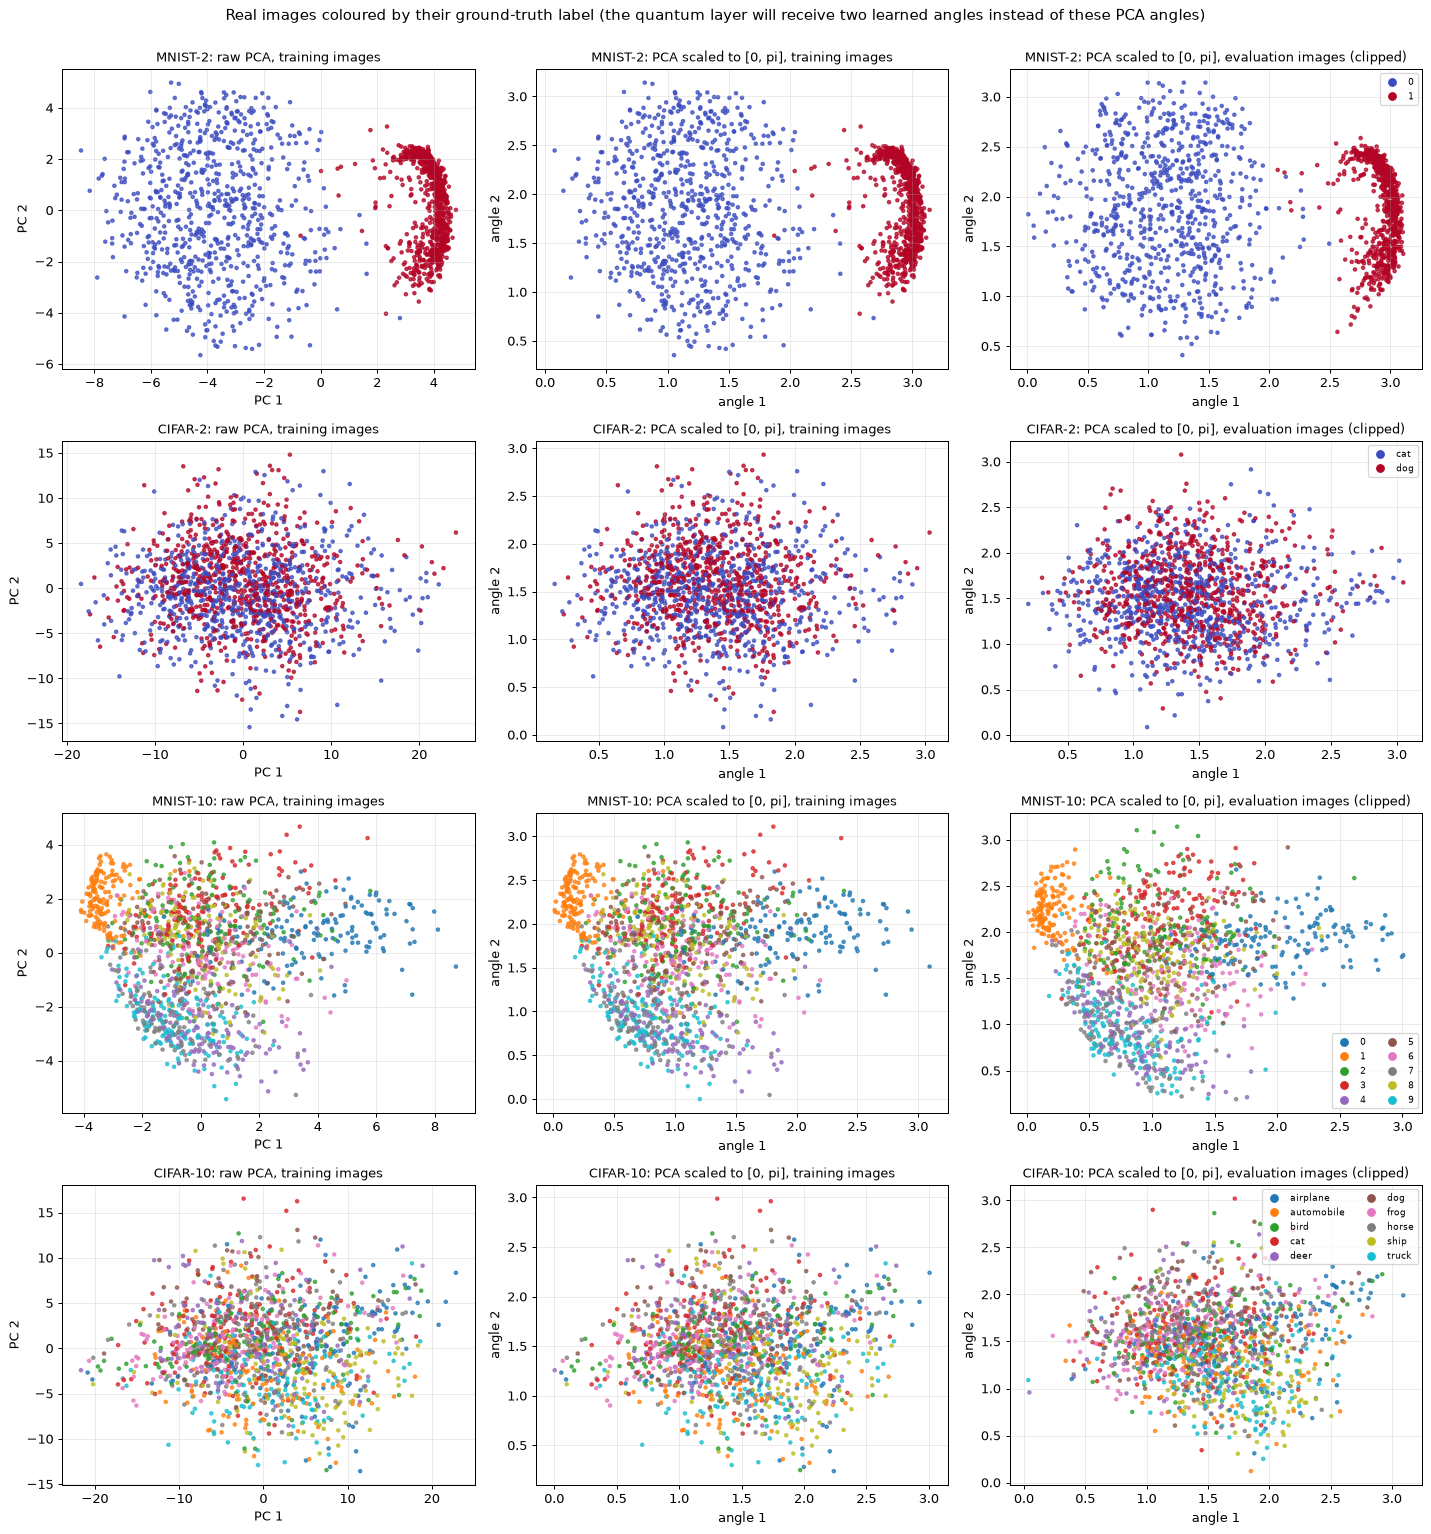

In [7]:
### Real observations in 2-D: raw PCA of the pixels, then the same coordinates scaled to [0, pi] (fitted on the training split only)
pca2, mm2, EMB = {}, {}, {}
fig, axs = plt.subplots(4, 3, figsize=(16, 17))
for r_, (n, t) in enumerate(TASKS.items()):
    flat = lambda x: x.reshape(len(x), -1)
    sub = np.random.default_rng(SEED).choice(len(t["x_train"]), min(3000, len(t["x_train"])), replace=False)
    pca2[n] = PCA(n_components=2, random_state=SEED).fit(flat(t["x_train"])[sub])
    z_tr, z_te = pca2[n].transform(flat(t["x_train"])), pca2[n].transform(flat(t["x_test"]))
    mm2[n] = MinMaxScaler((0, np.pi)).fit(z_tr)
    a_tr, a_te = mm2[n].transform(z_tr), np.clip(mm2[n].transform(z_te), 0, np.pi)
    EMB[n] = (z_tr, a_tr, z_te, a_te)
    cmap = "tab10" if t["n_classes"] > 2 else "coolwarm"
    for j, (P, y, ttl) in enumerate([(z_tr, t["y_train"], "raw PCA, training images"), (a_tr, t["y_train"], "PCA scaled to [0, pi], training images"),
                                     (a_te, t["y_test"], "PCA scaled to [0, pi], evaluation images (clipped)")]):
        ax = axs[r_, j]
        take = np.random.default_rng(SEED).choice(len(P), min(1500, len(P)), replace=False)
        sc = ax.scatter(P[take, 0], P[take, 1], c=y[take], cmap=cmap, s=7, alpha=.75, vmin=0, vmax=max(1, t["n_classes"] - 1))
        ax.set_title(f"{n}: {ttl}", fontsize=10); ax.set_xlabel("PC 1" if j == 0 else "angle 1"); ax.set_ylabel("PC 2" if j == 0 else "angle 2")
        if j == 2:
            handles = [plt.Line2D([], [], marker="o", ls="", color=plt.get_cmap(cmap)(k / max(1, t["n_classes"] - 1)), label=cn) for k, cn in enumerate(t["class_names"])]
            ax.legend(handles=handles, fontsize=7, ncol=2 if t["n_classes"] > 2 else 1, loc="best")
plt.suptitle("Real images coloured by their ground-truth label (the quantum layer will receive two learned angles instead of these PCA angles)", y=1.0)
plt.tight_layout(); plt.show()

## 2. The quantum layer as one gate list, and an independent check

The whole quantum part of the victim is described **once**, as a plain gate list `(name, qubits, parameters)`. The same list is
(a) replayed in a PennyLane QNode (used for training, the attacks and the figures), and (b) converted into a Qiskit `QuantumCircuit`
(used for an independent exact statevector check and for CNOT counting). A SQUASH attack is just an extra list of malicious
insertions `(slot, kind, qubits)`; `slot` is the place inside the variational circuit where the gate is spliced in:

| slot | position |
|---|---|
| 0 | right after the feature map |
| 1 | after the first ansatz layer (rotations + CNOT) |
| 2 | after the last ansatz rotations, immediately before the measurement / SWAP test |

Qubit 0 is the ancilla of the SWAP test, qubits 1 and 2 are the two data qubits. The *untargeted* attack inserts random SWAP gates between any
two of the three qubits (the ancilla included); a *SWAP test* variant inserts `H - CSWAP - H` blocks.

**Readouts.** The classical head needs the qubit outputs *and* the fidelity. A SWAP test is a measurement of the ancilla that disturbs the
two data qubits (their marginals are averaged by the controlled SWAP), so the readouts are taken from two runs of the same circuit:
`<Z1>`, `<Z2>` from the circuit *without* the test block, and `P(0) = (1 + <Z_ancilla>)/2` from the circuit *with* it. For the state
`rho` of the two data qubits just before the test, `P(0) = (1 + Tr[rho SWAP])/2` (equation 6 of the paper is the special case of a product state).

In [8]:
N_PARAMS = 12                       # efficient_su2(2, reps=2): 3 rotation layers x 2 qubits x (RY, RZ)
PAIRS = [(0, 1), (0, 2), (1, 2)]    # qubit pairs a SWAP can act on (qubit 0 = ancilla)

def build_ops(x, th, attack=(), swap_test=True):
    """Gate list of the quantum layer. x: two angles (scalars or batch tensors), th: 12 variational parameters.
    attack: tuple of (slot, kind, qubits) with kind in {'SWAP', 'SWAPTEST'}; for SWAPTEST qubits = (control, a, b)."""
    ops = []
    # --- feature map: zz_feature_map(2, reps=1), written out. CHOICE: the paper only says 'feature map layer' on 2 qubits
    for q in (1, 2): ops.append(("H", (q,), ()))
    ops.append(("RZ", (1,), (2 * x[..., 0],))); ops.append(("RZ", (2,), (2 * x[..., 1],)))
    ops.append(("CNOT", (1, 2), ())); ops.append(("RZ", (2,), (2 * (np.pi - x[..., 0]) * (np.pi - x[..., 1]),))); ops.append(("CNOT", (1, 2), ()))
    ops.append(("SLOT", (), (0,)))
    # --- ansatz: efficient_su2(2, reps=2) layout. CHOICE: the paper only says 'variational ansatz'
    k = 0
    for layer in range(3):
        for q in (1, 2):
            ops.append(("RY", (q,), (th[k],))); k += 1
            ops.append(("RZ", (q,), (th[k],))); k += 1
        if layer < 2:
            ops.append(("CNOT", (1, 2), ()))
            if layer == 0: ops.append(("SLOT", (), (1,)))                  # slot 1: after the first ansatz layer (rotations + CNOT)
    ops.append(("SLOT", (), (2,)))
    # --- splice in the malicious gates (SQUASH)
    out = []
    for o in ops:
        out.append(o)
        if o[0] == "SLOT":
            for (s, kind, qs) in attack:
                if s == o[2][0]:
                    if kind == "SWAP": out.append(("SWAP", tuple(qs), ()))
                    else:
                        c, a, b = qs
                        out += [("H", (c,), ()), ("CSWAP", (c, a, b), ()), ("H", (c,), ())]
    out = [o for o in out if o[0] != "SLOT"]
    # --- measurement layer: the SWAP test between the two data qubits (ancilla = qubit 0)
    if swap_test:
        out += [("H", (0,), ()), ("CSWAP", (0, 1, 2), ()), ("H", (0,), ())]
    return out

def apply_pl(ops):
    for n, w, p in ops:
        if n == "H": qml.Hadamard(wires=w[0])
        elif n == "RZ": qml.RZ(p[0], wires=w[0])
        elif n == "RY": qml.RY(p[0], wires=w[0])
        elif n == "CNOT": qml.CNOT(wires=list(w))
        elif n == "SWAP": qml.SWAP(wires=list(w))
        elif n == "CSWAP": qml.CSWAP(wires=list(w))
        else: raise ValueError(n)

dev = qml.device("default.qubit", wires=3)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def qnode(x, th, attack=(), swap_test=True):
    apply_pl(build_ops(x, th, attack, swap_test))
    return [qml.expval(qml.PauliZ(0)), qml.expval(qml.PauliZ(1)), qml.expval(qml.PauliZ(2))]

# ---------------- a fast batched state-vector simulator that replays the SAME gate list (used for training and attacks) ----------------
# PennyLane's QNode is exact but spends most of its time on Python overhead; this 8-amplitude simulator is 20-50 times faster.
# It is asserted equal to the PennyLane QNode and to Qiskit below, so what is trained is the circuit that is drawn.
from functools import reduce
_I2, _H2 = np.eye(2), np.array([[1, 1], [1, -1]]) / np.sqrt(2)
_FIXED = {}
def _perm_matrix(f):
    M = np.zeros((8, 8))
    for idx in range(8):
        bits = [(idx >> 2) & 1, (idx >> 1) & 1, idx & 1]; o = f(bits); M[o[0] * 4 + o[1] * 2 + o[2], idx] = 1
    return M
def _fixed(name, w):
    key = (name, w)
    if key not in _FIXED:
        if name == "H":
            M = reduce(np.kron, [_H2 if i == w[0] else _I2 for i in range(3)])
        elif name == "CNOT":
            def f(b): b = list(b); b[w[1]] ^= b[w[0]]; return b
            M = _perm_matrix(f)
        elif name == "SWAP":
            def f(b): b = list(b); b[w[0]], b[w[1]] = b[w[1]], b[w[0]]; return b
            M = _perm_matrix(f)
        elif name == "CSWAP":
            def f(b):
                b = list(b)
                if b[w[0]]: b[w[1]], b[w[2]] = b[w[2]], b[w[1]]
                return b
            M = _perm_matrix(f)
        _FIXED[key] = torch.tensor(M, dtype=torch.complex128)
    return _FIXED[key]

def _rot(name, th):
    th = torch.as_tensor(th, dtype=torch.float64)
    if name == "RY":
        c, s = torch.cos(th / 2), torch.sin(th / 2)
        return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)
    e = torch.exp(-0.5j * th); z = torch.zeros_like(e)                                  # RZ(th) = diag(e^{-i th/2}, e^{+i th/2})
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)

def torch_sim(ops, B):
    """Replay a gate list on |000> for a batch of B inputs; returns the (B, 8) state vector (qubit 0 = most significant bit)."""
    st = torch.zeros(B, 8, dtype=torch.complex128); st[:, 0] = 1
    for n, w, p in ops:
        if n in ("RY", "RZ"):
            U = _rot(n, p[0]); q = w[0]
            s4 = torch.movedim(st.reshape(B, 2, 2, 2), q + 1, -1)
            s4 = torch.einsum("bxyj,ij->bxyi", s4, U) if U.dim() == 2 else torch.einsum("bxyj,bij->bxyi", s4, U)
            st = torch.movedim(s4, -1, q + 1).reshape(B, 8)
        else:
            st = st @ _fixed(n, tuple(w)).T
    return st

_ZSIGN = torch.tensor([[1 - 2 * ((i >> (2 - q)) & 1) for i in range(8)] for q in range(3)], dtype=torch.float64)   # Z_q eigenvalue of basis state i
def torch_expvals(x, th, attack=(), swap_test=True):
    """Same signature and result as `qnode`: the three <Z_q> as a (3, B) tensor."""
    x = torch.as_tensor(x, dtype=torch.float64)
    if x.dim() == 1: x = x[None]
    st = torch_sim(build_ops(x, th, attack, swap_test), x.shape[0])
    return ((st.abs() ** 2) @ _ZSIGN.T).T

def quantum_features(a, th, attack=()):
    """a: (B,2) angles (float64) -> (B,3) readouts [<Z1>, <Z2>, P(0)]."""
    z_plain = torch_expvals(a, th, attack, False).T
    z_test = torch_expvals(a, th, attack, True).T
    return torch.stack([z_plain[:, 1], z_plain[:, 2], (1 + z_test[:, 0]) / 2], -1)

# ---------------- independent Qiskit version of the same gate list ----------------
def to_qiskit(ops):
    qc = QuantumCircuit(3)
    for n, w, p in ops:
        if n == "H": qc.h(w[0])
        elif n == "RZ": qc.rz(float(p[0]), w[0])
        elif n == "RY": qc.ry(float(p[0]), w[0])
        elif n == "CNOT": qc.cx(*w)
        elif n == "SWAP": qc.swap(*w)
        elif n == "CSWAP": qc.cswap(*w)
    return qc

def qiskit_z(qc):
    sv = Statevector(qc)
    return np.array([sv.expectation_value(SparsePauliOp.from_sparse_list([("Z", [i], 1.0)], 3)).real for i in range(3)]), sv

# ---------------- equivalence assertion: PennyLane QNode == Qiskit statevector, for random inputs and attacks ----------------
GATES = [(s, "SWAP", p) for s in range(3) for p in PAIRS]
from qiskit.quantum_info import Operator
_qs = QuantumCircuit(3); _qs.swap(1, 2); swap_op = Operator(_qs)        # the SWAP operator on the two data qubits
r_ =np.random.default_rng(1)
worst, swap_err, n_formula = 0.0, 0.0, 0
for trial in range(30):
    x = r_.uniform(-np.pi, np.pi, 2); th = r_.uniform(-np.pi, np.pi, N_PARAMS)
    k = r_.integers(0, 4)
    att = tuple(GATES[i] for i in r_.integers(0, len(GATES), k))
    if trial % 3 == 0: att = att + ((int(r_.integers(0, 3)), "SWAPTEST", tuple(int(v) for v in r_.permutation(3))),)
    for st in (False, True):
        pl = torch.stack(qnode(torch.tensor(x), torch.tensor(th), att, st)).numpy()
        qk, _ = qiskit_z(to_qiskit(build_ops(x, th, att, st)))
        ts = torch_expvals(torch.tensor(x), torch.tensor(th), att, st)[:, 0].numpy()
        worst = max(worst, np.abs(pl - qk).max(), np.abs(ts - qk).max())
    # P(0) = (1 + <SWAP_12>)/2 on the state just before the test (paper eq. 6 generalised to entangled data qubits).
    # It holds whenever the ancilla is still |0> at that point, i.e. for attacks that do not touch qubit 0.
    if all(0 not in g[2] for g in att):
        _, sv_before = qiskit_z(to_qiskit(build_ops(x, th, att, False)))
        pl_t = torch.stack(qnode(torch.tensor(x), torch.tensor(th), att, True)).numpy()
        p0_formula = (1 + sv_before.expectation_value(swap_op).real) / 2
        swap_err = max(swap_err, abs((1 + pl_t[0]) / 2 - p0_formula)); n_formula += 1
print(f"max deviation between PennyLane QNode, fast torch simulator and Qiskit statevector over 30 random circuits/attacks, both measurement settings: {worst:.2e}")
print(f"max |P(0) from the circuit - (1 + <SWAP_12>)/2| : {swap_err:.2e} ({n_formula} circuits with an untouched ancilla)")
assert worst < 1e-9 and swap_err < 1e-9 and n_formula > 0
print("EQUIVALENCE ASSERTION PASSED: the simulator that is trained = the PennyLane QNode that is drawn = the exact Qiskit statevector simulation.")

max deviation between PennyLane QNode, fast torch simulator and Qiskit statevector over 30 random circuits/attacks, both measurement settings: 4.44e-16
max |P(0) from the circuit - (1 + <SWAP_12>)/2| : 4.44e-16 (8 circuits with an untouched ancilla)
EQUIVALENCE ASSERTION PASSED: the simulator that is trained = the PennyLane QNode that is drawn = the exact Qiskit statevector simulation.


## Quantum Circuit Architecture

The figures below draw the circuits that are **actually executed**: the PennyLane QNode `qnode` built from `build_ops`, which was just
asserted equal to an exact Qiskit simulation, and the Qiskit circuit made from the very same gate list. Three distinct architectures
are compared:

1. **clean victim**: feature map, ansatz (12 trainable parameters), SWAP test on qubits (1, 2) with the ancilla (qubit 0);
2. **untargeted SQUASH**: the same circuit with k = 3 random malicious SWAP gates spliced into the variational part (drawn with the placement of
   the first random draw of the k = 3 experiment in section 7); one with a malicious SWAP *test* as well;
3. **targeted SQUASH**: two malicious SWAP gates (the actual attacker-selected pair is drawn again in section 8 after the search).

Assumptions that the paper omits are listed in the "What follows the paper" table (feature map, ansatz, qubit order, ancilla position,
where the SWAP gates sit).

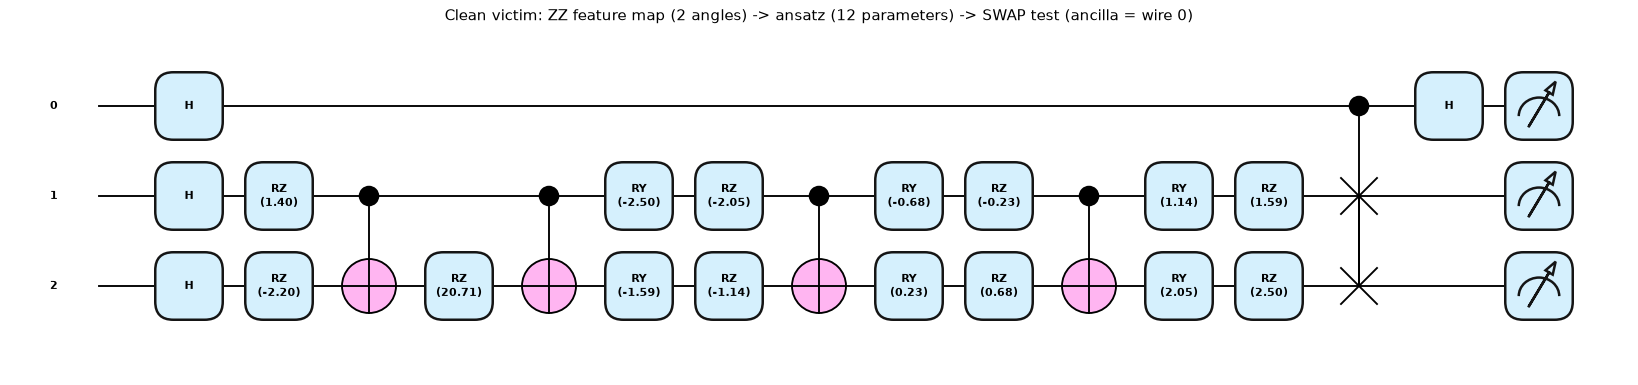

clean circuit: qubits = 3 (2 data + 1 ancilla), gates = 24, depth = 15, trainable parameters = 12


In [9]:
### Clean victim circuit (PennyLane QNode, drawn from the gate list that is executed)
x_demo = torch.tensor([0.7, -1.1], dtype=torch.float64)
th_demo = torch.linspace(-2.5, 2.5, N_PARAMS, dtype=torch.float64)
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane", fontsize=9)(x_demo, th_demo, (), True)
fig.suptitle("Clean victim: ZZ feature map (2 angles) -> ansatz (12 parameters) -> SWAP test (ancilla = wire 0)", y=1.02); plt.show()
n_gate = len(build_ops(x_demo.numpy(), th_demo.numpy(), (), True))
qc_clean = to_qiskit(build_ops(x_demo.numpy(), th_demo.numpy(), (), True))
print(f"clean circuit: qubits = {qc_clean.num_qubits} (2 data + 1 ancilla), gates = {n_gate}, depth = {qc_clean.depth()}, trainable parameters = {N_PARAMS}")

untargeted attack, k = 3 malicious SWAP gates (slot, kind, qubits): ((0, 'SWAP', (0, 1)), (1, 'SWAP', (0, 1)), (1, 'SWAP', (0, 2)))


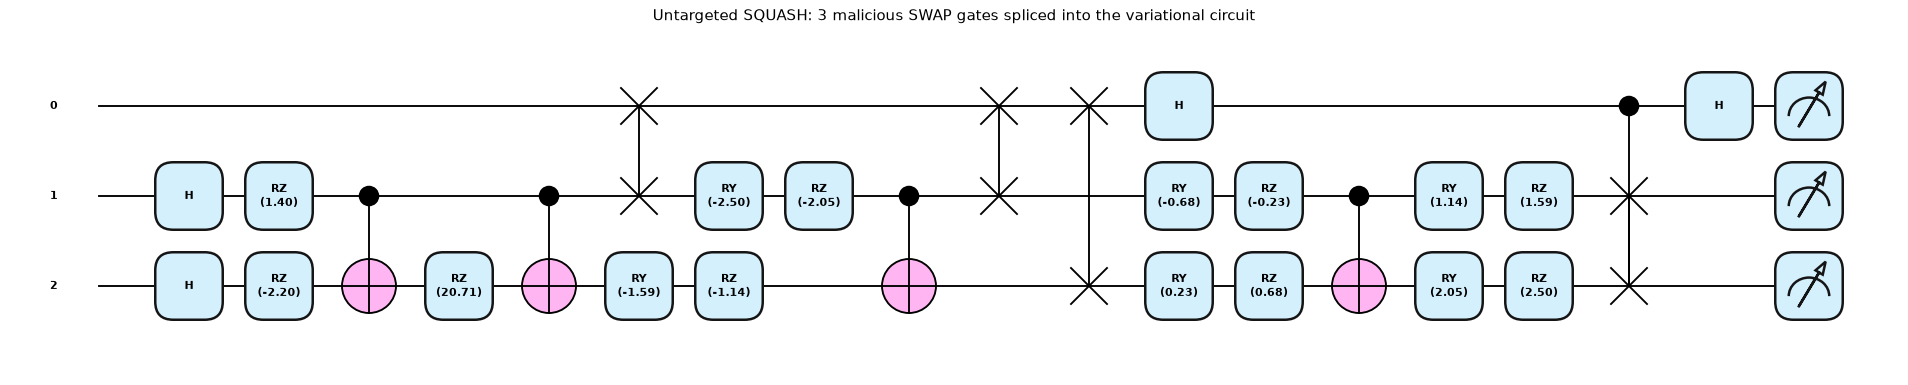

   qubits = 3, depth = 18 (clean: 15), gates = 27 (clean: 24), trainable parameters = 12 (the attack adds none)
SWAP-test insertion (malicious H - CSWAP - H after the first ansatz layer): ((1, 'SWAPTEST', (0, 1, 2)),)


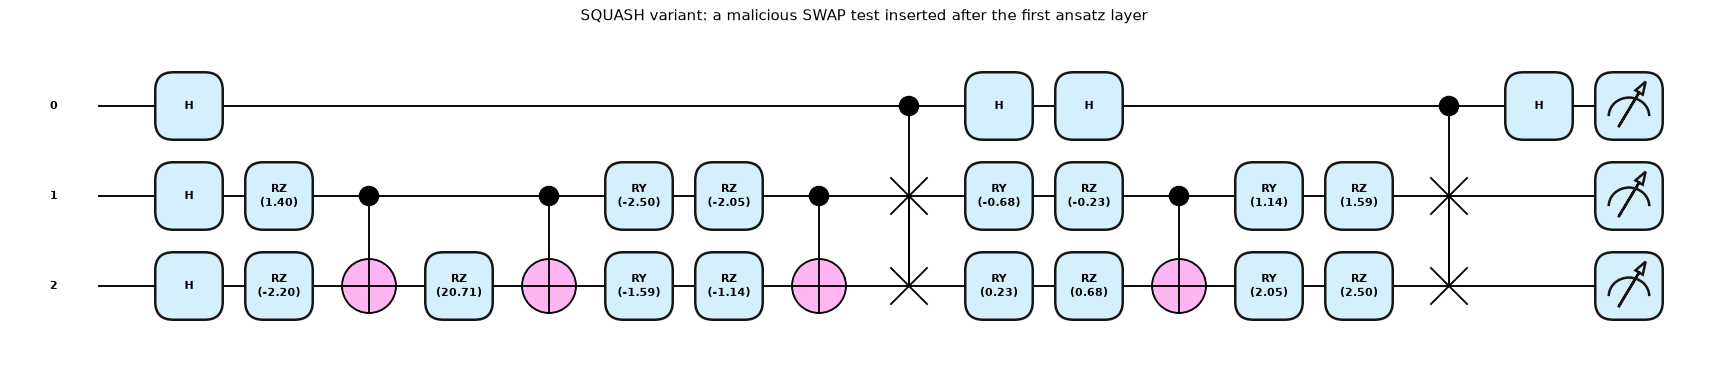

   qubits = 3, depth = 16 (clean: 15), gates = 27 (clean: 24), trainable parameters = 12 (the attack adds none)
targeted attack shape (two SWAP gates; the real selection happens in section 8): ((0, 'SWAP', (0, 1)), (2, 'SWAP', (1, 2)))


Matplotlib is building the font cache; this may take a moment.


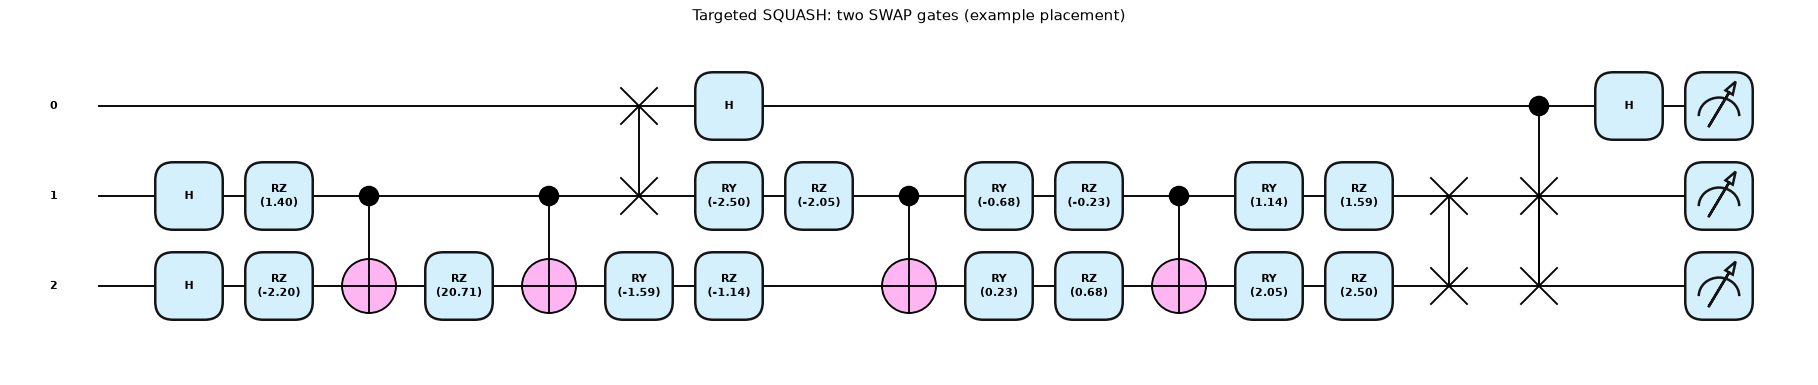

   qubits = 3, depth = 17 (clean: 15), gates = 26 (clean: 24), trainable parameters = 12 (the attack adds none)


In [10]:
### Attacked circuits: untargeted (k = 3 random SWAP gates, with the placement used in section 7) and a SWAP-test insertion
def draw_attack(att, title):
    fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane", fontsize=9)(x_demo, th_demo, att, True)
    fig.suptitle(title, y=1.02); plt.show()
    qc = to_qiskit(build_ops(x_demo.numpy(), th_demo.numpy(), att, True))
    print(f"   qubits = {qc.num_qubits}, depth = {qc.depth()} (clean: {qc_clean.depth()}), gates = {len(qc.data)} (clean: {len(qc_clean.data)}), trainable parameters = {N_PARAMS} (the attack adds none)")
    return qc

def sample_swaps(r, k):
    """k random malicious SWAP gates: uniform slot in {0,1,2}, uniform qubit pair among the three pairs (ancilla included)."""
    return tuple((int(r.integers(0, 3)), "SWAP", PAIRS[int(r.integers(0, 3))]) for _ in range(k))

def sample_tests(r, k):
    """k random malicious SWAP tests: uniform slot, random (control, a, b) permutation of the three qubits."""
    return tuple((int(r.integers(0, 3)), "SWAPTEST", tuple(int(v) for v in r.permutation(3))) for _ in range(k))

ATT_DEMO = sample_swaps(np.random.default_rng(SEED + 100), 3)         # also the first draw of the k = 3 untargeted experiment
print("untargeted attack, k = 3 malicious SWAP gates (slot, kind, qubits):", ATT_DEMO)
qc_unt = draw_attack(ATT_DEMO, "Untargeted SQUASH: 3 malicious SWAP gates spliced into the variational circuit")
ATT_ST = ((1, "SWAPTEST", (0, 1, 2)),)
print("SWAP-test insertion (malicious H - CSWAP - H after the first ansatz layer):", ATT_ST)
qc_st = draw_attack(ATT_ST, "SQUASH variant: a malicious SWAP test inserted after the first ansatz layer")
ATT_TG_DEMO = ((0, "SWAP", (0, 1)), (2, "SWAP", (1, 2)))
print("targeted attack shape (two SWAP gates; the real selection happens in section 8):", ATT_TG_DEMO)
qc_tg = draw_attack(ATT_TG_DEMO, "Targeted SQUASH: two SWAP gates (example placement)")

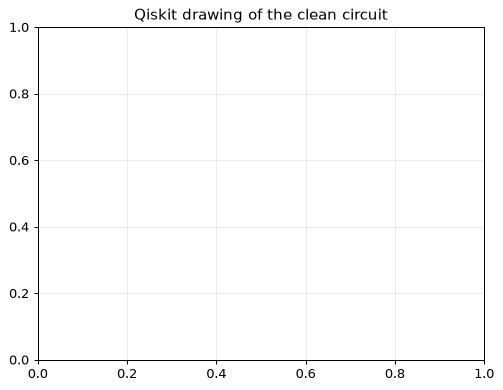

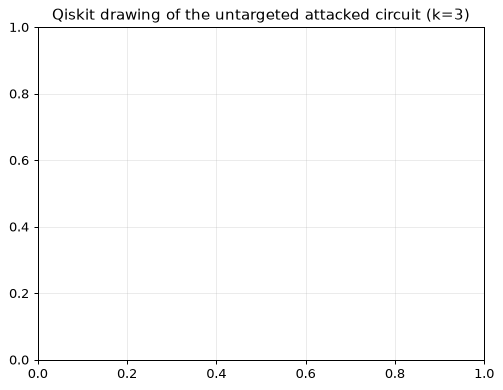

,circuit,qubits,depth,transpiled_cx,transpiled_depth,params,extra_cx_vs_clean
0,clean,3,15,12,26,12,0
1,untargeted k=3 SWAP gates,3,18,21,35,12,9
2,SWAP-test insertion,3,16,20,39,12,8
3,targeted 2 SWAP gates,3,17,18,32,12,6


CNOTs in one SWAP gate after decomposition: 3 (paper: three CNOTs per SWAP)


In [11]:
### The same circuits in Qiskit (independent drawing of the same gate lists), and the CNOT cost of a SWAP
qc_clean.draw("mpl", fold=40, style="iqp"); plt.title("Qiskit drawing of the clean circuit"); plt.show()
qc_unt.draw("mpl", fold=40, style="iqp"); plt.title("Qiskit drawing of the untargeted attacked circuit (k=3)"); plt.show()

def cx_count(qc): return transpile(qc, basis_gates=["cx", "u"], optimization_level=0).count_ops().get("cx", 0)
rows = [("clean", qc_clean), ("untargeted k=3 SWAP gates", qc_unt), ("SWAP-test insertion", qc_st), ("targeted 2 SWAP gates", qc_tg)]
tab = pd.DataFrame([dict(circuit=n, qubits=q.num_qubits, depth=q.depth(), transpiled_cx=cx_count(q), transpiled_depth=transpile(q, basis_gates=["cx", "u"], optimization_level=0).depth(), params=N_PARAMS) for n, q in rows])
tab["extra_cx_vs_clean"] = tab.transpiled_cx - tab.transpiled_cx.iloc[0]
display(tab)
one = QuantumCircuit(3); one.swap(0, 1)
print("CNOTs in one SWAP gate after decomposition:", cx_count(one), "(paper: three CNOTs per SWAP)")

## 3. The hybrid model (victim) and its classical counterpart

The classical front end follows Section IV-C: two convolutional layers, dropout, flatten, two fully connected layers, the second outputs
2 numbers. They are mapped to angles `pi * tanh(.)` in `(-pi, pi)` and enter the quantum layer; the three readouts go through a small fully
connected head to the class scores. The **classical counterpart** keeps the whole network but replaces the quantum layer by a small
classical layer `2 -> 8 -> 3` with `tanh`, so that the only difference is quantum or classical bottleneck.

In [12]:
class Net(nn.Module):
    def __init__(self, c_in, hw, n_classes, quantum=True):
        super().__init__()
        self.quantum = quantum
        self.conv1, self.conv2 = nn.Conv2d(c_in, 8, 3, padding=1), nn.Conv2d(8, 16, 3, padding=1)
        self.drop = nn.Dropout(0.25)
        self.fc1, self.fc2 = nn.Linear(16 * (hw // 8) ** 2, 32), nn.Linear(32, 2)      # CHOICE: input is 2x2 average-pooled first (CPU budget), so hw // 2 // 4
        if quantum:
            self.theta = nn.Parameter(torch.rand(N_PARAMS, dtype=torch.float64) * 2 * np.pi - np.pi)   # CHOICE: uniform in [-pi, pi)
        else:
            self.mid = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 3))
        self.head = nn.Sequential(nn.Linear(3, 32), nn.ReLU(), nn.Linear(32, n_classes))
    def angles(self, x):
        x = F.avg_pool2d(x, 2)                                         # CHOICE: 2x2 average pooling of the image before the CNN (CPU budget)
        h = F.max_pool2d(F.relu(self.conv1(x)), 2)
        h = F.max_pool2d(F.relu(self.conv2(h)), 2)
        h = self.drop(h).flatten(1)
        return np.pi * torch.tanh(self.fc2(F.relu(self.fc1(h))))
    def qfeat(self, a, attack=()):
        if self.quantum:
            return quantum_features(a.double(), self.theta, attack).float()
        return self.mid(a)
    def forward(self, x, attack=()):
        return self.head(self.qfeat(self.angles(x), attack))

def n_params(m): return sum(p.numel() for p in m.parameters())

@torch.no_grad()
def get_angles(m, x, bs=512):
    m.eval(); return torch.cat([m.angles(torch.from_numpy(x[i:i + bs])) for i in range(0, len(x), bs)])

@torch.no_grad()
def logits_from_angles(m, A, attack=(), bs=1024):
    m.eval(); return torch.cat([m.head(m.qfeat(A[i:i + bs], attack)) for i in range(0, len(A), bs)])

def metrics(logits, y):
    y_t = torch.as_tensor(y)
    pred = logits.argmax(1).numpy()
    nll = F.cross_entropy(logits, y_t).item()
    acc = float((pred == y).mean())
    pc = np.array([(pred[y == c] == c).mean() if (y == c).any() else np.nan for c in range(logits.shape[1])])
    return dict(acc=100 * acc, nll=nll, per_class=100 * pc, pred=pred)

def train_model(task, seed, quantum=True, attack_train=(), epochs=None, verbose=True):
    set_seeds(seed)
    c_in, hw = task["x_train"].shape[1], task["x_train"].shape[2]
    m = Net(c_in, hw, task["n_classes"], quantum)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    X, Y = torch.from_numpy(task["x_train"]), torch.from_numpy(task["y_train"]).long()
    n_val = int(VAL_FRAC * len(X)); X_val, Y_val, X_fit, Y_fit = X[:n_val], Y[:n_val], X[n_val:], Y[n_val:]
    epochs = epochs or SPEC[task["name"]][3]
    hist, t0 = [], time.time()
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(X_fit)); tot = 0.0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            loss = F.cross_entropy(m(X_fit[idx], attack_train), Y_fit[idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        m.eval()
        with torch.no_grad():
            val = (m(X_val, attack_train).argmax(1) == Y_val).float().mean().item() * 100
        hist.append((tot / len(perm), val))
        if verbose: print(f"  [{task['name']} seed {seed}{' quantum' if quantum else ' classical'}{' attacked-training' if attack_train else ''}] epoch {ep + 1}/{epochs} train loss {hist[-1][0]:.4f}  val acc {val:.1f} %  ({time.time() - t0:.0f} s)")
    return m, hist

m_demo = Net(3, 32, 10, True); m_cl = Net(3, 32, 10, False)
print("hybrid quantum network: parameters", n_params(m_demo), "of which quantum", N_PARAMS, "| classical counterpart parameters", n_params(m_cl))

hybrid quantum network: parameters 10152 of which quantum 12 | classical counterpart parameters 10191


## 4. Classical baselines on identical inputs

The paper compares nothing against classical models, but the brief of this project asks for baselines on the **same images**. A random
forest and an RBF-SVM are trained on the 50 leading PCA components of the raw pixels (scaler and PCA fitted on the training split only).
The classical counterpart network of section 3 (same CNN, classical 2-to-3 layer instead of the quantum layer) is trained together with the
hybrid model in section 5. These baselines are never attacked by SQUASH (they have no quantum circuit), but section 10 shows that the same
kind of damage can be done to the classical counterpart by permuting its bottleneck units.

In [13]:
BASE = []
for name, task in TASKS.items():
    flat = lambda x: x.reshape(len(x), -1)
    sc = StandardScaler().fit(flat(task["x_train"]))
    pca = PCA(n_components=50, random_state=SEED).fit(sc.transform(flat(task["x_train"])))
    Z_tr, Z_te = (pca.transform(sc.transform(flat(task[s]))) for s in ("x_train", "x_test"))
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, n_jobs=2, random_state=SEED).fit(Z_tr, task["y_train"])
    acc_rf = 100 * accuracy_score(task["y_test"], rf.predict(Z_te)); t_rf = time.time() - t0
    n_svc = min(len(Z_tr), 5000)                                  # CHOICE: SVC fitted on at most 5000 training images (time)
    t0 = time.time(); svc = SVC(kernel="rbf", C=1.0, random_state=SEED).fit(Z_tr[:n_svc], task["y_train"][:n_svc])
    acc_svc = 100 * accuracy_score(task["y_test"], svc.predict(Z_te)); t_svc = time.time() - t0
    BASE.append(dict(task=name, RandomForest=acc_rf, SVC_rbf=acc_svc, rf_s=t_rf, svc_s=t_svc))
BASE = pd.DataFrame(BASE).set_index("task")
display(BASE.round(2))

,RandomForest,SVC_rbf,rf_s,svc_s
task,,,,
MNIST-2,99.68,99.36,7.41,0.29
CIFAR-2,64.06,65.00,18.08,4.54
MNIST-10,92.88,93.88,24.75,2.48
CIFAR-10,42.60,43.05,31.89,6.07


## 5. Train the clean victim (and its classical counterpart)

One hybrid quantum model and one classical counterpart per task and seed, same data, same optimiser, same number of epochs. The attacks act
on the trained hybrid model. Training uses exact expectation values and back-propagation through the PennyLane simulator.

In [14]:
MODELS, ANG, CLEAN = {}, {}, []
t_start = time.time()
for name, task in TASKS.items():
    for seed in SEEDS:
        t0 = time.time()
        mq, hq = train_model(task, seed, True, verbose=(seed == SEEDS[0]))
        mc, hc = train_model(task, seed, False, verbose=False)
        MODELS[(name, seed)] = (mq, mc, hq, hc)
        ANG[(name, seed)] = {"q": {s: get_angles(mq, task["x_" + s]) for s in ("probe", "test")}, "c": {s: get_angles(mc, task["x_" + s]) for s in ("probe", "test")}}
        ANG[(name, seed)]["q"]["train"] = get_angles(mq, task["x_train"][:1500])
        mt_q = metrics(logits_from_angles(mq, ANG[(name, seed)]["q"]["test"]), task["y_test"])
        mt_c = metrics(logits_from_angles(mc, ANG[(name, seed)]["c"]["test"]), task["y_test"])
        CLEAN.append(dict(task=name, seed=seed, hybrid_acc=mt_q["acc"], hybrid_nll=mt_q["nll"], classical_cnn_acc=mt_c["acc"], classical_cnn_nll=mt_c["nll"], train_s=time.time() - t0))
        print(f"{name:9s} seed {seed}: hybrid acc {mt_q['acc']:.2f} % (NLL {mt_q['nll']:.3f}) | classical counterpart {mt_c['acc']:.2f} % | {time.time() - t0:.0f} s")
CLEAN = pd.DataFrame(CLEAN)
print(f"total training time {time.time() - t_start:.0f} s")

  [MNIST-2 seed 42 quantum] epoch 1/8 train loss 0.2558  val acc 99.7 %  (5 s)


  [MNIST-2 seed 42 quantum] epoch 2/8 train loss 0.0145  val acc 99.5 %  (10 s)


  [MNIST-2 seed 42 quantum] epoch 3/8 train loss 0.0139  val acc 99.0 %  (15 s)


  [MNIST-2 seed 42 quantum] epoch 4/8 train loss 0.0089  val acc 99.5 %  (20 s)


  [MNIST-2 seed 42 quantum] epoch 5/8 train loss 0.0100  val acc 99.8 %  (25 s)


...

  [CIFAR-10 seed 42 quantum] epoch 13/14 train loss 1.7215  val acc 34.0 %  (153 s)


  [CIFAR-10 seed 42 quantum] epoch 14/14 train loss 1.7196  val acc 37.3 %  (164 s)


CIFAR-10  seed 42: hybrid acc 34.00 % (NLL 1.720) | classical counterpart 37.40 % | 214 s


CIFAR-10  seed 43: hybrid acc 20.65 % (NLL 1.921) | classical counterpart 37.50 % | 227 s


CIFAR-10  seed 44: hybrid acc 27.85 % (NLL 1.884) | classical counterpart 36.95 % | 247 s
total training time 1926 s


,hybrid QNN acc %,std,hybrid NLL,classical-CNN acc %,RandomForest acc %,SVC(rbf) acc %
task,,,,,,
MNIST-2,99.91,0.10,0.003,99.96,99.68,99.36
CIFAR-2,60.29,8.97,0.643,62.79,64.06,65.00
MNIST-10,94.68,1.13,0.227,95.97,92.88,93.88
CIFAR-10,27.50,6.68,1.841,37.28,42.60,43.05


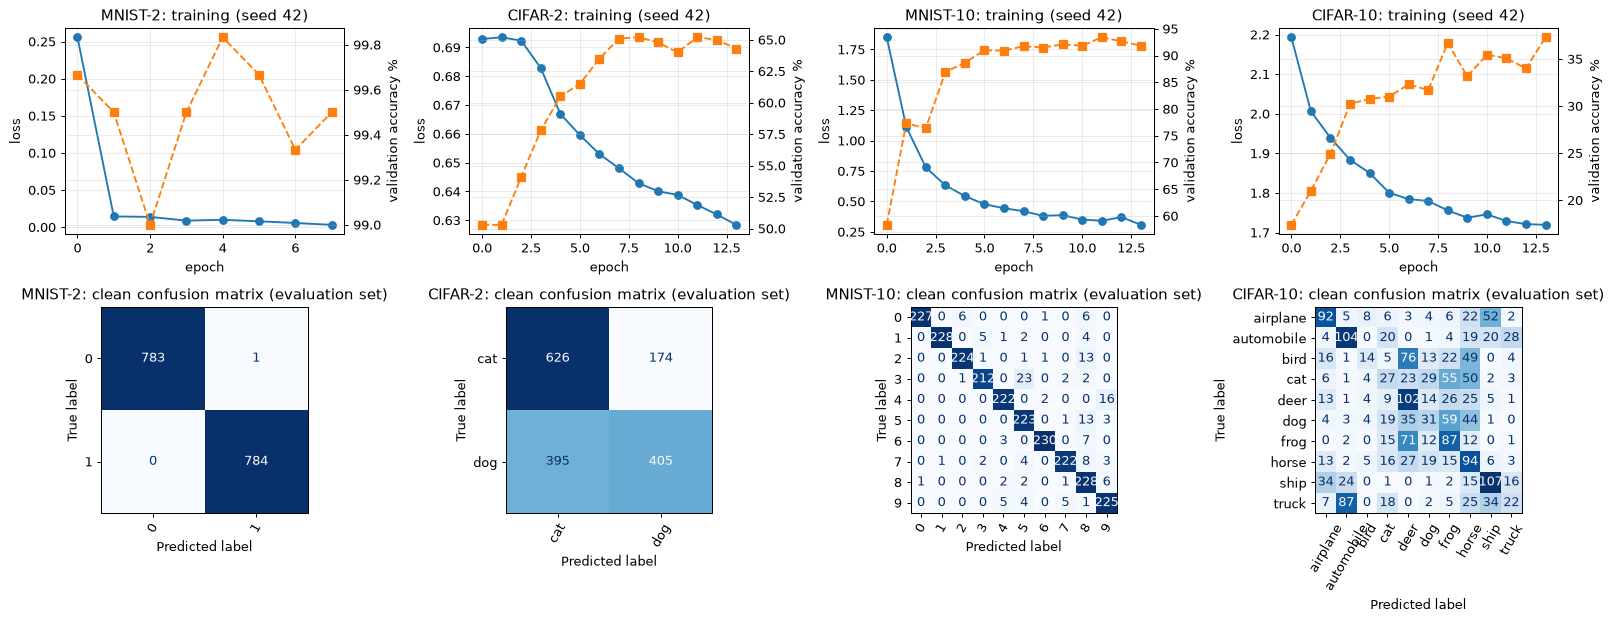

In [15]:
### Clean results (mean +- std over seeds), against the classical baselines
g = CLEAN.groupby("task", sort=False)
summ = pd.DataFrame({"hybrid QNN acc %": g.hybrid_acc.mean().round(2), "std": g.hybrid_acc.std().fillna(0).round(2), "hybrid NLL": g.hybrid_nll.mean().round(3),
                     "classical-CNN acc %": g.classical_cnn_acc.mean().round(2), "RandomForest acc %": BASE.RandomForest.round(2), "SVC(rbf) acc %": BASE.SVC_rbf.round(2)})
display(summ)

fig, axs = plt.subplots(2, 4, figsize=(18, 7))
for j, (name, task) in enumerate(TASKS.items()):
    mq, mc, hq, hc = MODELS[(name, SEEDS[0])]
    ax = axs[0, j]; ax.plot([h[0] for h in hq], "o-", label="train loss"); ax2 = ax.twinx(); ax2.plot([h[1] for h in hq], "s--", color="C1", label="val acc %")
    ax.set_title(f"{name}: training (seed {SEEDS[0]})"); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax2.set_ylabel("validation accuracy %")
    cm = confusion_matrix(task["y_test"], metrics(logits_from_angles(mq, ANG[(name, SEEDS[0])]["q"]["test"]), task["y_test"])["pred"])
    ConfusionMatrixDisplay(cm, display_labels=task["class_names"]).plot(ax=axs[1, j], colorbar=False, xticks_rotation=60, cmap="Blues")
    axs[1, j].set_title(f"{name}: clean confusion matrix (evaluation set)"); axs[1, j].grid(False)
plt.tight_layout(); plt.show()

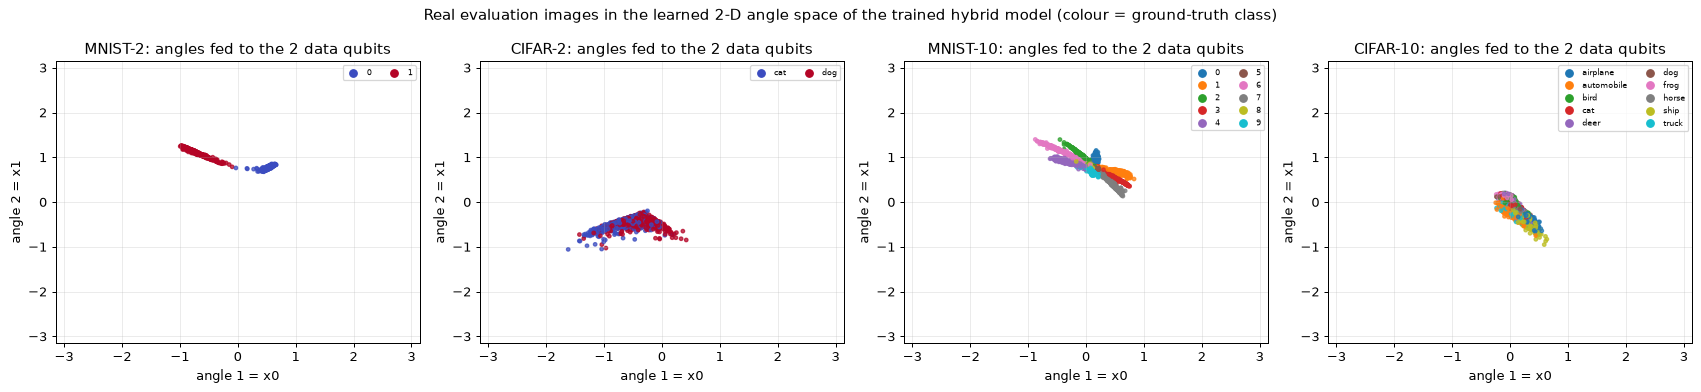

In [16]:
### What the quantum layer actually receives: the learned angles of real images, coloured by ground-truth label
fig, axs = plt.subplots(1, 4, figsize=(19, 4.4))
for ax, (name, task) in zip(axs, TASKS.items()):
    A = ANG[(name, SEEDS[0])]["q"]["test"].numpy()
    sc_ = ax.scatter(A[:, 0], A[:, 1], c=task["y_test"], cmap="tab10" if task["n_classes"] > 2 else "coolwarm", s=8, alpha=.75, vmin=0, vmax=max(1, task["n_classes"] - 1))
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi); ax.set_xlabel("angle 1 = x0"); ax.set_ylabel("angle 2 = x1")
    ax.set_title(f"{name}: angles fed to the 2 data qubits");
    handles = [plt.Line2D([], [], marker="o", ls="", color=plt.get_cmap("tab10" if task["n_classes"] > 2 else "coolwarm")(k / max(1, task["n_classes"] - 1)), label=cn) for k, cn in enumerate(task["class_names"])]
    ax.legend(handles=handles, fontsize=6, ncol=2, loc="upper right")
plt.suptitle("Real evaluation images in the learned 2-D angle space of the trained hybrid model (colour = ground-truth class)"); plt.tight_layout(); plt.show()

## 6. Quantum readouts of the clean model

Before attacking, look at the three numbers per image that the head receives: `<Z1>`, `<Z2>` and the SWAP-test probability `P(0)`.
A SWAP gate moves these numbers between wires, so a head that was trained to expect `P(0)` in the third input suddenly receives something
else. The table shows how much the readouts of the evaluation images change when the circuit is attacked (here a single SWAP between
the two data qubits right before the test, then one that involves the ancilla).

,attack,mean_Z1,mean_Z2,mean_P0,mean_abs_change
0,clean,0.002,-0.106,0.859,0.000
1,"SWAP(1,2) at slot 2",-0.106,0.002,0.859,0.409
2,"SWAP(0,1) at slot 2",1.000,-0.106,0.457,0.467
3,"SWAP(0,2) at slot 0",-0.007,-0.015,0.657,0.334


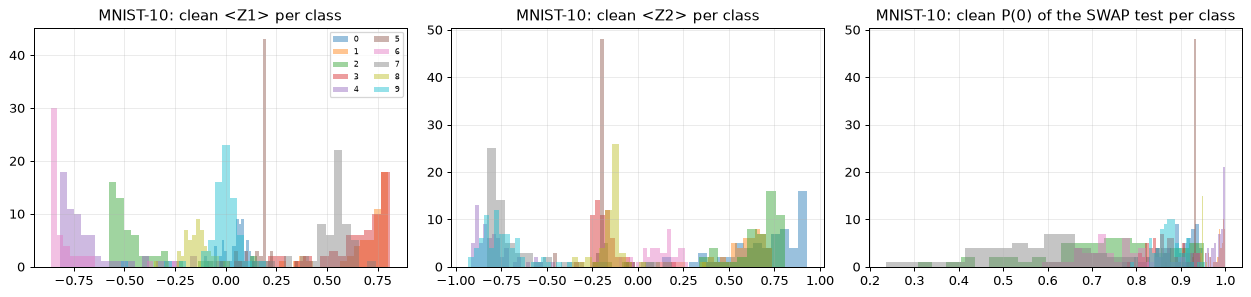

In [17]:
name = "MNIST-10" if "MNIST-10" in TASKS else list(TASKS)[0]
mq = MODELS[(name, SEEDS[0])][0]; A = ANG[(name, SEEDS[0])]["q"]["test"][:600]
with torch.no_grad():
    f_clean = mq.qfeat(A).numpy()
    rows = []
    for label, att in [("clean", ()), ("SWAP(1,2) at slot 2", ((2, "SWAP", (1, 2)),)), ("SWAP(0,1) at slot 2", ((2, "SWAP", (0, 1)),)), ("SWAP(0,2) at slot 0", ((0, "SWAP", (0, 2)),))]:
        f = mq.qfeat(A, att).numpy()
        rows.append(dict(attack=label, mean_Z1=f[:, 0].mean(), mean_Z2=f[:, 1].mean(), mean_P0=f[:, 2].mean(), mean_abs_change=np.abs(f - f_clean).mean()))
display(pd.DataFrame(rows).round(3))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for j, nm in enumerate(["<Z1>", "<Z2>", "P(0) of the SWAP test"]):
    for c in range(TASKS[name]["n_classes"]):
        axs[j].hist(f_clean[TASKS[name]["y_test"][:600] == c, j], bins=20, alpha=.45, label=TASKS[name]["class_names"][c])
    axs[j].set_title(f"{name}: clean {nm} per class")
axs[0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()

## 7. Untargeted SQUASH: random SWAP gates in the trained circuit

For each number of malicious SWAPs `k` = 1, 2, 3 the notebook draws many random placements (slot and qubit pair uniformly at random,
ancilla included), inserts them into the trained circuit, **keeps the trained weights** (the classical layers and the head are not retrained) and
measures accuracy and NLL on the evaluation set. The paper reports a single accuracy per `k`; here the mean over the random draws, the
standard deviation and the worst single draw are shown ("untargeted SWAP attacks reducing accuracy by up to ..."). A second variant inserts
malicious SWAP *tests* (`H - CSWAP - H`) instead of plain SWAP gates.

In [18]:
UNT = []
t0 = time.time()
for name, task in TASKS.items():
    for seed in SEEDS:
        mq = MODELS[(name, seed)][0]; A = ANG[(name, seed)]["q"]["test"]; y = task["y_test"]
        for kind, sampler in (("SWAP gate", sample_swaps), ("SWAP test", sample_tests)):
            for k in K_LIST:
                off = (0 if k == 3 else k) + (500 if kind == "SWAP test" else 0) + 7919 * (seed - SEED)
                r = np.random.default_rng(SEED + 100 + off)               # for seed 42, SWAP gate, k = 3 the first draw equals ATT_DEMO
                for d in range(A_DRAWS):
                    att = sampler(r, k)
                    m = metrics(logits_from_angles(mq, A, att), y)
                    UNT.append(dict(task=name, seed=seed, kind=kind, k=k, draw=d, acc=m["acc"], nll=m["nll"], attack=att))
UNT = pd.DataFrame(UNT)
assert UNT[(UNT.kind == "SWAP gate") & (UNT.k == 3) & (UNT.seed == SEEDS[0]) & (UNT.draw == 0)].attack.iloc[0] == ATT_DEMO
print(f"{len(UNT)} attacked evaluations in {time.time() - t0:.0f} s")
clean_mean = CLEAN.groupby("task", sort=False).hybrid_acc.mean()
def agg(df):
    return pd.Series(dict(acc_mean=df.acc.mean(), acc_std=df.acc.std(), acc_worst=df.acc.min(), nll_mean=df.nll.mean()))
UNT_S = UNT.groupby(["task", "kind", "k"], sort=False).apply(agg).reset_index()
UNT_S["clean_acc"] = UNT_S.task.map(clean_mean); UNT_S["drop_mean"] = UNT_S.clean_acc - UNT_S.acc_mean; UNT_S["drop_worst"] = UNT_S.clean_acc - UNT_S.acc_worst
display(UNT_S.round(2))

2160 attacked evaluations in 154 s


,task,kind,k,acc_mean,acc_std,acc_worst,nll_mean,clean_acc,drop_mean,drop_worst
0,MNIST-2,SWAP gate,1,69.71,33.96,0.06,1.12,99.91,30.20,99.85
1,MNIST-2,SWAP gate,2,63.97,36.35,0.13,1.40,99.91,35.95,99.79
2,MNIST-2,SWAP gate,3,59.02,33.59,0.00,1.38,99.91,40.89,99.91
3,MNIST-2,SWAP test,1,88.44,20.24,50.00,0.25,99.91,11.47,49.91
4,MNIST-2,SWAP test,2,76.62,27.20,0.83,0.70,99.91,23.29,99.09
5,MNIST-2,SWAP test,3,73.63,27.59,1.59,0.64,99.91,26.29,98.32
6,CIFAR-2,SWAP gate,1,49.67,6.50,33.75,0.80,60.29,10.62,26.54
7,CIFAR-2,SWAP gate,2,52.09,6.40,33.69,0.79,60.29,8.20,26.60
8,CIFAR-2,SWAP gate,3,49.04,5.30,33.75,0.81,60.29,11.25,26.54
9,CIFAR-2,SWAP test,1,55.06,6.18,44.50,0.70,60.29,5.23,15.79


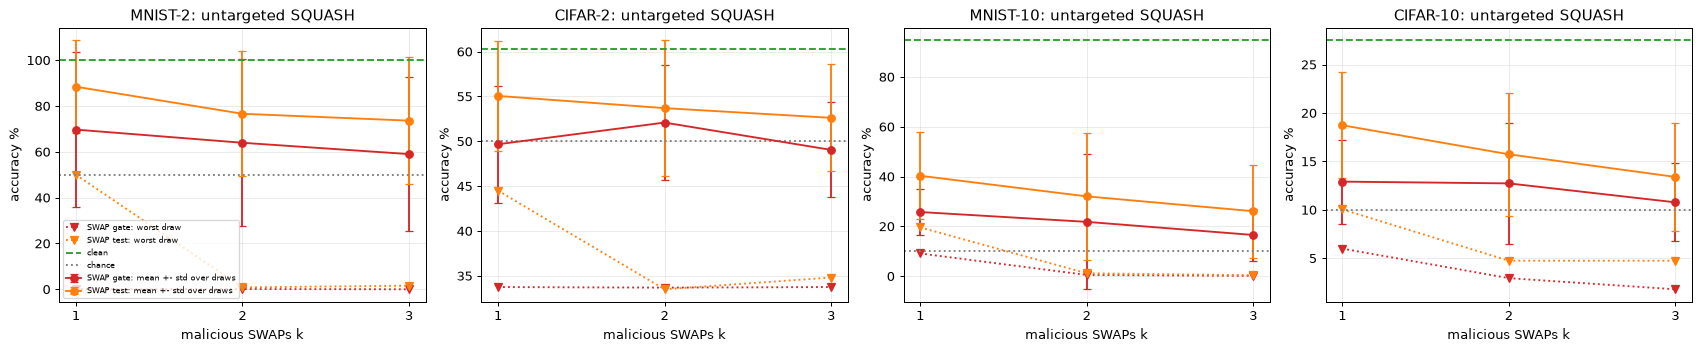

In [19]:
fig, axs = plt.subplots(1, 4, figsize=(19, 4))
for ax, (name, task) in zip(axs, TASKS.items()):
    for kind, col in (("SWAP gate", "C3"), ("SWAP test", "C1")):
        s = UNT_S[(UNT_S.task == name) & (UNT_S.kind == kind)]
        ax.errorbar(s.k, s.acc_mean, yerr=s.acc_std.fillna(0), fmt="o-", color=col, capsize=3, label=f"{kind}: mean +- std over draws")
        ax.plot(s.k, s.acc_worst, "v:", color=col, label=f"{kind}: worst draw")
    ax.axhline(clean_mean[name], color="C2", ls="--", label="clean"); ax.axhline(100 / task["n_classes"], color="grey", ls=":", label="chance")
    ax.set_xticks(K_LIST); ax.set_xlabel("malicious SWAPs k"); ax.set_ylabel("accuracy %"); ax.set_title(f"{name}: untargeted SQUASH")
axs[0].legend(fontsize=6); plt.tight_layout(); plt.show()

## 8. Targeted SQUASH: break one class, keep the rest

The attacker wants the target class `t` to be misclassified while the other classes still look healthy, so that the overall accuracy
stays acceptable. The paper formulates this as making `F(psi_t, chi) > F(psi_c, chi)` (Algorithm 1) with only two SWAP tests. As the
algorithm is not specified for a circuit-only attacker, this notebook implements the *same goal* as a black-box search:

1. The attacker has **no training data**. He sends the unlabeled probe images to the victim and records its answers (pseudo-labels).
2. He tries every circuit tampering made of at most two SWAP gates (9 single placements and 81 ordered pairs, 90 candidates).
3. For the chosen target class `t` he keeps the candidate that maximises `agreement(other classes) - agreement(class t)` with the
   pseudo-labels (a tiny penalty per gate prefers fewer gates).
4. The chosen tampering is then evaluated on the held-out evaluation set with the *true* labels.

The search is repeated for every class as target, so the table shows what the attacker can reach for each class and the best case ("up to").

In [20]:
CANDS = [(g,) for g in GATES] + [(a, b) for a in GATES for b in GATES]
print(len(CANDS), "candidate tamperings (<= 2 SWAP gates)")
TG, PRED_CACHE = [], {}
t0 = time.time()
for name, task in TASKS.items():
    for seed in SEEDS:
        mq = MODELS[(name, seed)][0]; A_pr, A_te = ANG[(name, seed)]["q"]["probe"], ANG[(name, seed)]["q"]["test"]
        pl = logits_from_angles(mq, A_pr).argmax(1).numpy()                       # pseudo-labels = victim's own answers
        preds = {c: logits_from_angles(mq, A_pr, c).argmax(1).numpy() for c in CANDS}
        PRED_CACHE[(name, seed)] = (pl, preds)
        clean = metrics(logits_from_angles(mq, A_te), task["y_test"])
        for t in range(task["n_classes"]):
            if (pl == t).sum() < 3 or (pl != t).sum() < 1: continue
            best, bj = (), -9
            for c, pr in preds.items():
                agree = pr == pl
                J = agree[pl != t].mean() - agree[pl == t].mean() - 1e-3 * len(c)
                if J > bj: best, bj = c, J
            m = metrics(logits_from_angles(mq, A_te, best), task["y_test"])
            others = np.nanmean(np.delete(m["per_class"], t))
            TG.append(dict(task=name, seed=seed, target=task["class_names"][t], t=t, gates=best, n_gates=len(best), J_probe=bj,
                           clean_target_acc=clean["per_class"][t], target_acc=m["per_class"][t], others_acc=others,
                           clean_total=clean["acc"], total_acc=m["acc"], nll=m["nll"], clean_nll=clean["nll"]))
TG = pd.DataFrame(TG)
print(f"targeted search done in {time.time() - t0:.0f} s")
show = TG[TG.seed == SEEDS[0]][["task", "target", "gates", "clean_target_acc", "target_acc", "others_acc", "clean_total", "total_acc"]]
display(show.round(2))

90 candidate tamperings (<= 2 SWAP gates)


targeted search done in 26 s


,task,target,gates,clean_target_acc,target_acc,others_acc,clean_total,total_acc
0,MNIST-2,0,"((0, SWAP, (0, 2)),)",99.87,0.26,100.00,99.94,50.13
1,MNIST-2,1,"((2, SWAP, (0, 1)),)",100.00,0.00,100.00,99.94,50.00
6,CIFAR-2,cat,"((0, SWAP, (0, 2)),)",78.25,0.00,100.00,64.44,50.00
7,CIFAR-2,dog,"((1, SWAP, (0, 1)),)",50.62,0.00,100.00,64.44,50.00
10,MNIST-10,0,"((1, SWAP, (0, 2)),)",94.58,0.00,40.00,93.38,36.00
11,MNIST-10,1,"((1, SWAP, (1, 2)), (2, SWAP, (1, 2)))",95.00,27.08,66.11,93.38,62.21
12,MNIST-10,2,"((1, SWAP, (0, 2)),)",93.33,0.00,40.00,93.38,36.00
13,MNIST-10,3,"((1, SWAP, (1, 2)), (2, SWAP, (1, 2)))",88.33,15.42,67.41,93.38,62.21
14,MNIST-10,4,"((1, SWAP, (0, 2)),)",92.50,2.50,39.72,93.38,36.00
15,MNIST-10,5,"((1, SWAP, (1, 2)), (2, SWAP, (1, 2)))",92.92,1.67,68.94,93.38,62.21


,clean_total,mean_over_targets_target_acc,mean_over_targets_total_acc,best_target_target_acc,best_target_total_acc,best_target_nll,best_target_clean_target_acc
task,,,,,,,
MNIST-2,99.91,0.04,50.02,0.0,50.00,1.87,99.87
CIFAR-2,65.44,0.22,49.73,0.0,50.00,0.98,76.44
MNIST-10,94.68,2.10,37.00,0.0,32.29,4.06,96.11
CIFAR-10,28.61,2.71,16.41,0.0,16.57,2.21,33.67


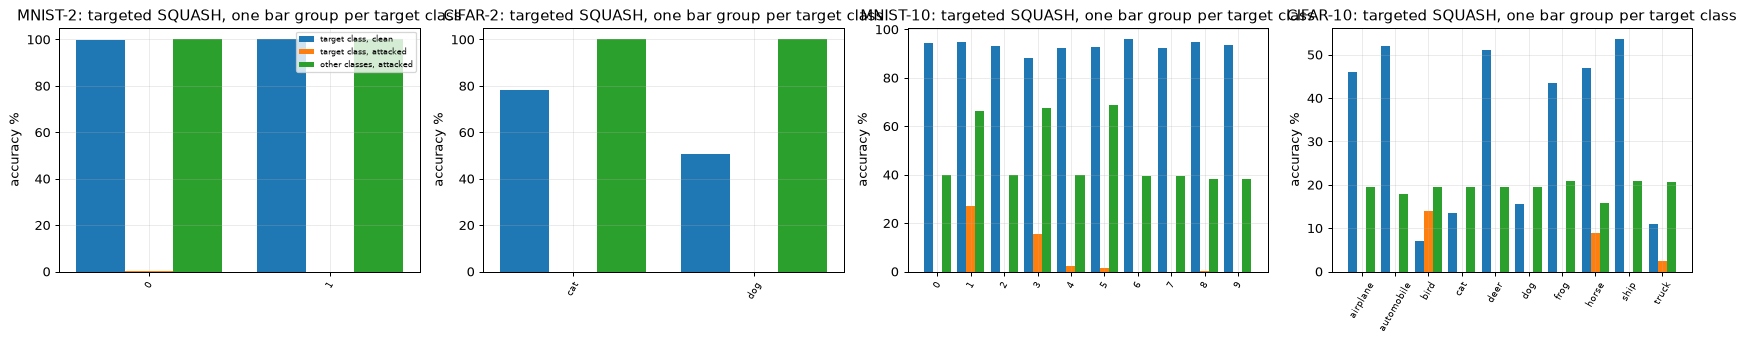

In [21]:
### Summary per task: mean over all targets and the attacker's best target (lowest target-class accuracy), averaged over seeds
rows = []
for name in TASKS:
    d = TG[TG.task == name]
    best = d.loc[d.groupby("seed").target_acc.idxmin()]
    rows.append(dict(task=name, clean_total=d.clean_total.mean(), mean_over_targets_target_acc=d.target_acc.mean(), mean_over_targets_total_acc=d.total_acc.mean(),
                     best_target_target_acc=best.target_acc.mean(), best_target_total_acc=best.total_acc.mean(), best_target_nll=best.nll.mean(),
                     best_target_clean_target_acc=best.clean_target_acc.mean()))
TG_S = pd.DataFrame(rows).set_index("task"); display(TG_S.round(2))

fig, axs = plt.subplots(1, 4, figsize=(19, 3.9))
for ax, (name, task) in zip(axs, TASKS.items()):
    d = TG[(TG.task == name) & (TG.seed == SEEDS[0])]
    x = np.arange(len(d)); w = .27
    ax.bar(x - w, d.clean_target_acc, w, label="target class, clean"); ax.bar(x, d.target_acc, w, label="target class, attacked")
    ax.bar(x + w, d.others_acc, w, label="other classes, attacked"); ax.set_xticks(x); ax.set_xticklabels(d.target, rotation=60, fontsize=7)
    ax.set_ylabel("accuracy %"); ax.set_title(f"{name}: targeted SQUASH, one bar group per target class")
axs[0].legend(fontsize=6); plt.tight_layout(); plt.show()

MNIST-2: best target = 1, selected tampering ((2, 'SWAP', (0, 1)),): target-class accuracy 100.0 % -> 0.0 %, total accuracy 99.9 % -> 50.0 %


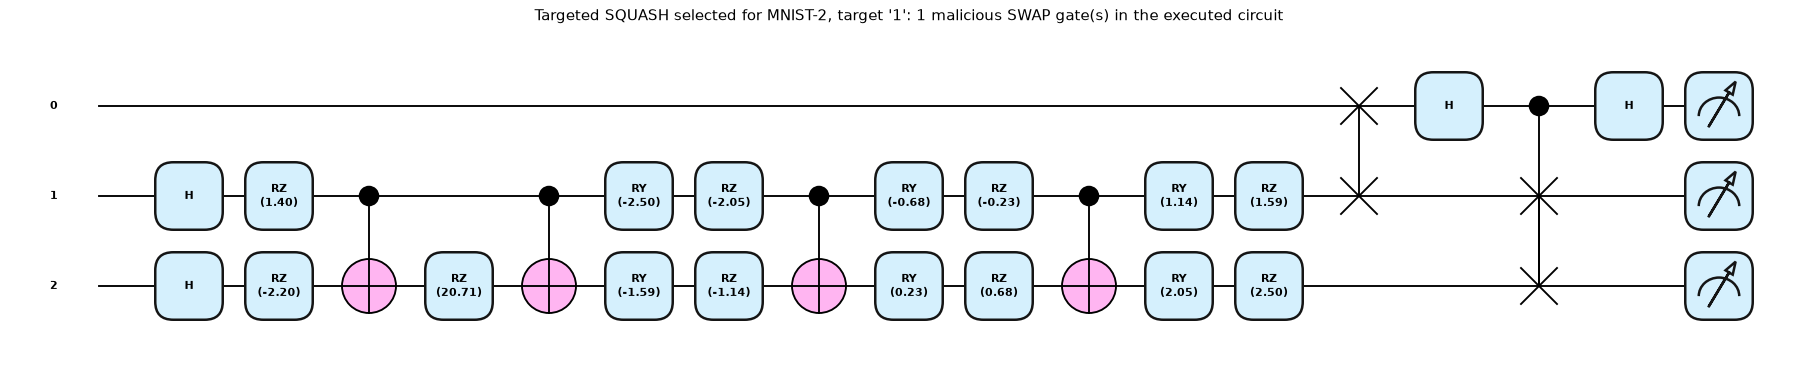

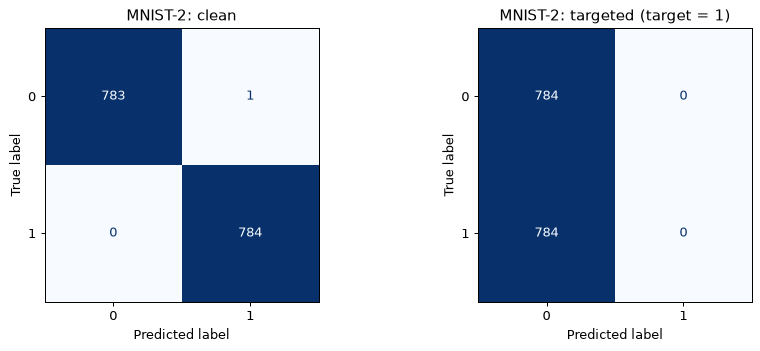

In [22]:
### The attacker-selected circuit for the best target of the first task, and the per-class damage on the confusion matrix
name = list(TASKS)[0]; task = TASKS[name]; seed = SEEDS[0]
d = TG[(TG.task == name) & (TG.seed == seed)]; row = d.loc[d.target_acc.idxmin()]
print(f"{name}: best target = {row.target}, selected tampering {row.gates}: target-class accuracy {row.clean_target_acc:.1f} % -> {row.target_acc:.1f} %, total accuracy {row.clean_total:.1f} % -> {row.total_acc:.1f} %")
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane", fontsize=9)(x_demo, th_demo, tuple(row.gates), True)
fig.suptitle(f"Targeted SQUASH selected for {name}, target '{row.target}': {len(row.gates)} malicious SWAP gate(s) in the executed circuit", y=1.02); plt.show()
mq = MODELS[(name, seed)][0]; A_te = ANG[(name, seed)]["q"]["test"]
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (ttl, att) in zip(axs, [("clean", ()), (f"targeted (target = {row.target})", tuple(row.gates))]):
    cm = confusion_matrix(task["y_test"], metrics(logits_from_angles(mq, A_te, att), task["y_test"])["pred"])
    ConfusionMatrixDisplay(cm, display_labels=task["class_names"]).plot(ax=ax, colorbar=False, cmap="Blues"); ax.set_title(f"{name}: {ttl}"); ax.grid(False)
plt.tight_layout(); plt.show()

## 9. Does retraining remove the damage?

All numbers above insert the SWAPs into a model that was trained **without** them. If the malicious configuration is already in place while
the victim trains, the classical layers and the head can adapt to the permuted wires. This experiment trains the hybrid model with the
attacker's strongest single SWAP gate (the one that disagrees most with the clean pseudo-labels on the probe images) already in the circuit.

In [23]:
RET = []
for name in RETRAIN_SETS:
    task = TASKS[name]; seed = SEEDS[0]; mq = MODELS[(name, seed)][0]
    pl, preds = PRED_CACHE[(name, seed)]
    singles = [c for c in CANDS if len(c) == 1]
    worst = min(singles, key=lambda c: (preds[c] == pl).mean())
    A_te = ANG[(name, seed)]["q"]["test"]
    clean = metrics(logits_from_angles(mq, A_te), task["y_test"])["acc"]
    attacked = metrics(logits_from_angles(mq, A_te, worst), task["y_test"])["acc"]
    m2, h2 = train_model(task, seed, True, attack_train=worst, verbose=False)
    A2 = get_angles(m2, task["x_test"])
    retrained = metrics(logits_from_angles(m2, A2, worst), task["y_test"])["acc"]
    RET.append(dict(task=name, strongest_single_SWAP=worst, clean_acc=clean, attack_inserted_after_training=attacked, attack_present_during_training=retrained))
    print(name, "done")
display(pd.DataFrame(RET).round(2))

MNIST-2 done


MNIST-10 done


,task,strongest_single_SWAP,clean_acc,attack_inserted_after_training,attack_present_during_training
0,MNIST-2,"((0, SWAP, (0, 2)),)",99.94,50.13,99.81
1,MNIST-10,"((2, SWAP, (0, 1)),)",93.38,26.88,71.42


## 10. Is the damage specific to the quantum circuit? A classical analogue

Because the quantum layer only passes three numbers to the head, a SWAP that exchanges two wires is, from the head's point of view, a
permutation of input units. The classical counterpart has the same structure (three bottleneck units). Permuting two of its bottleneck
units after training - the classical analogue of SQUASH - shows how much of the effect is a property of "a trained head receives its inputs
in a different order" rather than of quantum mechanics.

In [24]:
CLS = []
for name, task in TASKS.items():
    for seed in SEEDS:
        mq, mc = MODELS[(name, seed)][0], MODELS[(name, seed)][1]
        Ac = ANG[(name, seed)]["c"]["test"]
        with torch.no_grad():
            f = mc.mid(Ac)
            accs = []
            for (i, j) in PAIRS:
                p = list(range(3)); p[i], p[j] = p[j], p[i]
                accs.append(100 * (mc.head(f[:, p]).argmax(1).numpy() == task["y_test"]).mean())
        CLS.append(dict(task=name, seed=seed, classical_clean=metrics(logits_from_angles(mc, Ac), task["y_test"])["acc"], classical_unit_swap_mean=np.mean(accs), classical_unit_swap_worst=np.min(accs)))
CLS = pd.DataFrame(CLS)
tab = CLS.groupby("task", sort=False).mean().drop(columns="seed")
tab["quantum_1_SWAP_mean"] = UNT_S[(UNT_S.kind == "SWAP gate") & (UNT_S.k == 1)].set_index("task").acc_mean
display(tab.round(2))

,classical_clean,classical_unit_swap_mean,classical_unit_swap_worst,quantum_1_SWAP_mean
task,,,,
MNIST-2,99.96,61.10,33.38,69.71
CIFAR-2,62.79,53.50,46.94,49.67
MNIST-10,95.97,27.37,9.18,25.76
CIFAR-10,37.28,21.93,13.08,12.92


## 11. SWAP overhead

The paper measures +5.96 % run time per epoch for the targeted attack (two SWAP tests) and +16.05 % for the untargeted one, and attributes
it to the three CNOTs per SWAP. Here the CNOT count is read from the transpiled Qiskit circuit and the run time of the simulated quantum layer is
measured on the evaluation images (a state-vector simulator, so this is *not* the cost on a quantum computer). On a shared CPU the measured simulator times of the three circuits differ by less than the timing noise (a few percent, and sometimes the attacked circuit even comes out faster), so only the CNOT count is a reliable overhead measure in this notebook; the paper-style run-time percentages cannot be checked with a simulator.

,model,transpiled_cx,extra_cx,layer_time_s,increase_pct
0,clean,12,0,0.036,0.000
1,targeted (2 SWAP gates),18,6,0.034,-4.359
2,untargeted (3 SWAP gates),21,9,0.033,-7.758


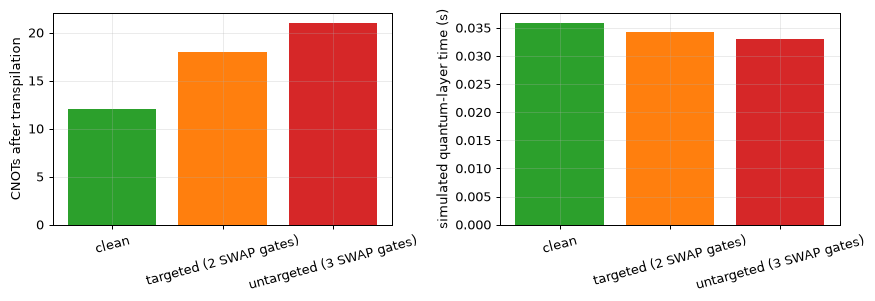

In [25]:
name = list(TASKS)[0]; mq = MODELS[(name, SEEDS[0])][0]; A = ANG[(name, SEEDS[0])]["q"]["test"].double()
def time_layers(atts, reps=40, inner=4):
    """Best-of-`reps` wall time of `inner` forward passes of the quantum layer on all evaluation images, for several circuits.
    The circuits are timed in interleaved order so that load changes on a shared CPU hit all of them alike; min is robust to spikes."""
    best = [np.inf] * len(atts)
    with torch.no_grad():
        for att in atts: quantum_features(A, mq.theta, att)                       # warm-up
        for _ in range(reps):
            for j, att in enumerate(atts):
                t0 = time.perf_counter()
                for _ in range(inner): quantum_features(A, mq.theta, att)
                best[j] = min(best[j], (time.perf_counter() - t0) / inner)
    return best
cases = [("clean", (), qc_clean), ("targeted (2 SWAP gates)", ATT_TG_DEMO, qc_tg), ("untargeted (3 SWAP gates)", ATT_DEMO, qc_unt)]
times = time_layers([c[1] for c in cases])
OH = [dict(model=lab, transpiled_cx=cx_count(qc), extra_cx=cx_count(qc) - cx_count(qc_clean), layer_time_s=t_, increase_pct=100 * (t_ / times[0] - 1)) for (lab, att, qc), t_ in zip(cases, times)]
OH = pd.DataFrame(OH); display(OH.round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(OH.model, OH.transpiled_cx, color=["C2", "C1", "C3"]); ax[0].set_ylabel("CNOTs after transpilation"); ax[0].tick_params(axis="x", labelrotation=15)
ax[1].bar(OH.model, OH.layer_time_s, color=["C2", "C1", "C3"]); ax[1].set_ylabel("simulated quantum-layer time (s)"); ax[1].tick_params(axis="x", labelrotation=15)
plt.tight_layout(); plt.show()

## 12. Paper versus this notebook

Paper numbers are copied from Tables I and II and from Section V-D. A numeric claim is **reproduced** when the notebook value is within 2
accuracy points (0.02 for NLL) of the paper; otherwise it is **not reached** (the notebook is lower for a clean model, weaker for an
attack) or **exceeded** (higher clean accuracy, stronger attack), with the gap.

In [26]:
PAPER = {
 "MNIST-2":  dict(clean=[96.01, 95.68, 95.30], clean_nll=[.0451, .0510, .0687], unt=[43.91, 35.22, 21.78], unt_nll=[.512, .649, .778], tg_target=19.14, tg_total=57.075, tg_clean=95.68, tg_nll=.823),
 "CIFAR-2":  dict(clean=[90.78, 91.41, 91.87], clean_nll=[.1102, .1127, .1210], unt=[38.04, 30.92, 18.12], unt_nll=[.599, .769, .932], tg_target=18.12, tg_total=54.062, tg_clean=91.38, tg_nll=.932),
 "MNIST-10": dict(clean=[93.11, 93.88, 93.89], clean_nll=[.0991, .0904, .0904], unt=[38.27, 32.64, 19.31], unt_nll=[.598, .701, .880], tg_target=20.94, tg_total=85.164, tg_clean=92.3, tg_nll=.801),
 "CIFAR-10": dict(clean=[77.42, 78.36, 78.92], clean_nll=[.1723, .1771, .1817], unt=[34.07, 27.18, 15.84], unt_nll=[.651, .744, .911], tg_target=15.84, tg_total=73.919, tg_clean=78.92, tg_nll=.911),
}
def verdict(ours, paper, kind, tol=2.0):
    gap = ours - paper
    if abs(gap) <= tol: return "reproduced"
    if kind == "clean":   return f"not reached ({gap:+.1f})" if gap < 0 else f"exceeded ({gap:+.1f})"
    return f"attack weaker than paper ({gap:+.1f})" if gap > 0 else f"attack stronger than paper ({gap:+.1f})"     # kind == "attacked": lower accuracy = stronger attack

rows = []
for name in TASKS:
    P = PAPER[name]; c = CLEAN[CLEAN.task == name]
    rows.append(dict(claim=f"{name}: clean accuracy (Table I, k=1)", paper=P["clean"][0], notebook=f"{c.hybrid_acc.mean():.2f} +- {c.hybrid_acc.std() if len(c) > 1 else 0:.2f}", verdict=verdict(c.hybrid_acc.mean(), P["clean"][0], "clean")))
    for k in K_LIST:
        s = UNT_S[(UNT_S.task == name) & (UNT_S.kind == "SWAP gate") & (UNT_S.k == k)].iloc[0]
        rows.append(dict(claim=f"{name}: untargeted attack, k={k} SWAP gates, accuracy (Table I)", paper=P["unt"][k - 1], notebook=f"{s.acc_mean:.2f} (worst draw {s.acc_worst:.2f})", verdict=verdict(s.acc_mean, P["unt"][k - 1], "attacked")))
    t = TG_S.loc[name]
    rows.append(dict(claim=f"{name}: targeted attack, target-class accuracy (Table II)", paper=P["tg_target"], notebook=f"best target {t.best_target_target_acc:.2f} (mean over targets {t.mean_over_targets_target_acc:.2f})", verdict=verdict(t.best_target_target_acc, P["tg_target"], "attacked")))
    rows.append(dict(claim=f"{name}: targeted attack, total accuracy (Table II)", paper=P["tg_total"], notebook=f"{t.best_target_total_acc:.2f} (mean over targets {t.mean_over_targets_total_acc:.2f})", verdict=verdict(t.best_target_total_acc, P["tg_total"], "attacked")))
CMP = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 100):
    display(CMP)

,claim,paper,notebook,verdict
0,"MNIST-2: clean accuracy (Table I, k=1)",96.010,99.91 +- 0.10,exceeded (+3.9)
1,"MNIST-2: untargeted attack, k=1 SWAP gates, accuracy (Table I)",43.910,69.71 (worst draw 0.06),attack weaker than paper (+25.8)
2,"MNIST-2: untargeted attack, k=2 SWAP gates, accuracy (Table I)",35.220,63.97 (worst draw 0.13),attack weaker than paper (+28.7)
3,"MNIST-2: untargeted attack, k=3 SWAP gates, accuracy (Table I)",21.780,59.02 (worst draw 0.00),attack weaker than paper (+37.2)
4,"MNIST-2: targeted attack, target-class accuracy (Table II)",19.140,best target 0.00 (mean over targets 0.04),attack stronger than paper (-19.1)
5,"MNIST-2: targeted attack, total accuracy (Table II)",57.075,50.00 (mean over targets 50.02),attack stronger than paper (-7.1)
6,"CIFAR-2: clean accuracy (Table I, k=1)",90.780,60.29 +- 8.97,not reached (-30.5)
7,"CIFAR-2: untargeted attack, k=1 SWAP gates, accuracy (Table I)",38.040,49.67 (worst draw 33.75),attack weaker than paper (+11.6)
8,"CIFAR-2: untargeted attack, k=2 SWAP gates, accuracy (Table I)",30.920,52.09 (worst draw 33.69),attack weaker than paper (+21.2)
9,"CIFAR-2: untargeted attack, k=3 SWAP gates, accuracy (Table I)",18.120,49.04 (worst draw 33.75),attack weaker than paper (+30.9)


In [27]:
### Qualitative claims and the abstract's headline numbers
q = []
mono = all((UNT_S[(UNT_S.task == n) & (UNT_S.kind == "SWAP gate")].sort_values("k").acc_mean.diff().dropna() < 0).all() for n in TASKS)
q.append(("Untargeted accuracy decreases monotonically with the number of malicious SWAPs (k = 1 -> 3) on every task",
          "reproduced" if mono else "not reached: " + "; ".join(f"{n}: " + ", ".join(f"{v:.1f}" for v in UNT_S[(UNT_S.task == n) & (UNT_S.kind == 'SWAP gate')].sort_values('k').acc_mean) for n in TASKS)))
q.append(("Untargeted SWAPs push accuracy close to or below chance (paper: 15.8-43.9 %)",
          "; ".join(f"{n} k=3: {UNT_S[(UNT_S.task == n) & (UNT_S.kind == 'SWAP gate') & (UNT_S.k == 3)].acc_mean.iloc[0]:.1f} % (chance {100 / TASKS[n]['n_classes']:.0f} %)" for n in TASKS)))
red = (UNT_S[UNT_S.kind == "SWAP gate"].groupby("task").drop_worst.max())
q.append(("Abstract: untargeted attacks reduce accuracy 'by up to 74.08 %' (percentage points, k = 3 on MNIST-10 in Table I: 93.89 - 19.31 = 74.58)",
          f"largest worst-draw drop here: {red.max():.1f} points ({red.idxmax()}) -> " + ("reproduced" if abs(red.max() - 74.08) <= 2 else ("exceeded" if red.max() > 74.08 else "not reached"))))
tg_drop = (TG_S.best_target_clean_target_acc - TG_S.best_target_target_acc)
q.append(("Abstract: targeted attacks reduce target-class accuracy 'by up to 79.78 %' (cannot be derived from Table II, whose largest clean-minus-target gap is 76.5 points)",
          f"largest target-class drop here: {tg_drop.max():.1f} points ({tg_drop.idxmax()}) -> cannot be checked exactly; Table II gap not reached" if tg_drop.max() < 76.5 - 2 else f"largest target-class drop here: {tg_drop.max():.1f} points ({tg_drop.idxmax()})"))
stealth = [(n, TG_S.loc[n, "clean_total"] - TG_S.loc[n, "best_target_total_acc"], tg_drop[n]) for n in TASKS]
q.append(("Targeted attack is stealthy: total accuracy falls much less than target-class accuracy (Table II)",
          "; ".join(f"{n}: total -{a:.1f} vs target -{b:.1f}" for n, a, b in stealth) + (" -> reproduced" if all(a < b for _, a, b in stealth) else " -> not on every task")))
q.append(("Overhead: targeted attack +5.96 %, untargeted +16.05 % run time (3 CNOTs per SWAP)",
          f"CNOTs per SWAP {int(OH.extra_cx.iloc[1] / 2)} (reproduced); simulator layer time: targeted {OH.increase_pct.iloc[1]:+.1f} %, untargeted {OH.increase_pct.iloc[2]:+.1f} % (a simulator, not an epoch time: cannot be checked on this basis)"))
q.append(("Attack needs no training data and no input perturbation", "reproduced by construction for both attacks here (inference-time SWAP insertion; the targeted search uses only unlabeled probe images)"))
q.append(("Impact if the SWAPs are already present during training", " ; ".join(f"{r['task']}: {r['attack_inserted_after_training']:.1f} % (inserted after training) vs {r['attack_present_during_training']:.1f} % (present during training; clean {r['clean_acc']:.1f} %)" for r in RET)))
with pd.option_context("display.max_colwidth", 220):
    display(pd.DataFrame(q, columns=["claim", "result in this notebook"]))
n_ok = (CMP.verdict == "reproduced").sum()
print(f"\nnumeric rows reproduced within tolerance: {n_ok} of {len(CMP)}")

,claim,result in this notebook
0,Untargeted accuracy decreases monotonically with the number of malicious SWAPs (k = 1 -> 3) on every task,"not reached: MNIST-2: 69.7, 64.0, 59.0; CIFAR-2: 49.7, 52.1, 49.0; MNIST-10: 25.8, 21.8, 16.5; CIFAR-10: 12.9, 12.7, 10.8"
1,Untargeted SWAPs push accuracy close to or below chance (paper: 15.8-43.9 %),MNIST-2 k=3: 59.0 % (chance 50 %); CIFAR-2 k=3: 49.0 % (chance 50 %); MNIST-10 k=3: 16.5 % (chance 10 %); CIFAR-10 k=3: 10.8 % (chance 10 %)
2,"Abstract: untargeted attacks reduce accuracy 'by up to 74.08 %' (percentage points, k = 3 on MNIST-10 in Table I: 93.89 - 19.31 = 74.58)",largest worst-draw drop here: 99.9 points (MNIST-2) -> exceeded
3,"Abstract: targeted attacks reduce target-class accuracy 'by up to 79.78 %' (cannot be derived from Table II, whose largest clean-minus-target gap is 76.5 points)",largest target-class drop here: 99.9 points (MNIST-2)
4,Targeted attack is stealthy: total accuracy falls much less than target-class accuracy (Table II),MNIST-2: total -49.9 vs target -99.9; CIFAR-2: total -15.4 vs target -76.4; MNIST-10: total -62.4 vs target -96.1; CIFAR-10: total -12.0 vs target -33.7 -> reproduced
5,"Overhead: targeted attack +5.96 %, untargeted +16.05 % run time (3 CNOTs per SWAP)","CNOTs per SWAP 3 (reproduced); simulator layer time: targeted -4.4 %, untargeted -7.8 % (a simulator, not an epoch time: cannot be checked on this basis)"
6,Attack needs no training data and no input perturbation,reproduced by construction for both attacks here (inference-time SWAP insertion; the targeted search uses only unlabeled probe images)
7,Impact if the SWAPs are already present during training,MNIST-2: 50.1 % (inserted after training) vs 99.8 % (present during training; clean 99.9 %) ; MNIST-10: 26.9 % (inserted after training) vs 71.4 % (present during training; clean 93.4 %)



numeric rows reproduced within tolerance: 1 of 24


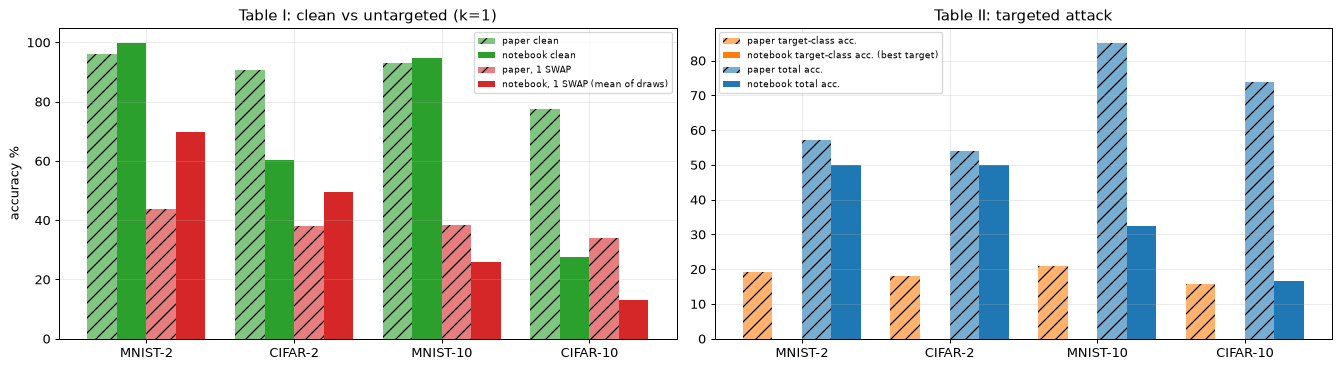

In [28]:
### Table I / II re-drawn: paper (hatched) against this notebook, clean and attacked accuracy
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
x = np.arange(len(TASKS)); w = .2
ours_clean = [clean_mean[n] for n in TASKS]
axs[0].bar(x - 1.5 * w, [PAPER[n]["clean"][0] for n in TASKS], w, color="C2", hatch="//", alpha=.6, label="paper clean")
axs[0].bar(x - .5 * w, ours_clean, w, color="C2", label="notebook clean")
for i, k in enumerate(K_LIST[:1]):
    axs[0].bar(x + .5 * w, [PAPER[n]["unt"][0] for n in TASKS], w, color="C3", hatch="//", alpha=.6, label="paper, 1 SWAP")
    axs[0].bar(x + 1.5 * w, [UNT_S[(UNT_S.task == n) & (UNT_S.kind == "SWAP gate") & (UNT_S.k == 1)].acc_mean.iloc[0] for n in TASKS], w, color="C3", label="notebook, 1 SWAP (mean of draws)")
axs[0].set_xticks(x); axs[0].set_xticklabels(list(TASKS)); axs[0].set_ylabel("accuracy %"); axs[0].set_title("Table I: clean vs untargeted (k=1)"); axs[0].legend(fontsize=7)
axs[1].bar(x - 1.5 * w, [PAPER[n]["tg_target"] for n in TASKS], w, color="C1", hatch="//", alpha=.6, label="paper target-class acc.")
axs[1].bar(x - .5 * w, [TG_S.loc[n, "best_target_target_acc"] for n in TASKS], w, color="C1", label="notebook target-class acc. (best target)")
axs[1].bar(x + .5 * w, [PAPER[n]["tg_total"] for n in TASKS], w, color="C0", hatch="//", alpha=.6, label="paper total acc.")
axs[1].bar(x + 1.5 * w, [TG_S.loc[n, "best_target_total_acc"] for n in TASKS], w, color="C0", label="notebook total acc.")
axs[1].set_xticks(x); axs[1].set_xticklabels(list(TASKS)); axs[1].set_title("Table II: targeted attack"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 13. Reading the paper critically

* **No code, several unspecified choices.** The feature map, the ansatz, the qubit that plays the ancilla, the way the readouts reach the
  final layer, the optimiser and the number of epochs are not given. Everything marked `# CHOICE:` above is therefore an assumption, and the
  absolute numbers of the clean model depend on it.
* **A 2-qubit bottleneck cannot be what delivers 93 % on MNIST-10 and 77 % on CIFAR-10 by itself.** The image is compressed by the classical layers into
  two numbers and the quantum layer returns three. The accuracy therefore measures mostly the classical front end; on CIFAR-10 this notebook's
  small CNN reaches far less than the paper's 77-79 %. The paper does not say how a 2-d quantum output carries ten classes, and it
  does not report a classical counterpart, so no quantum advantage and no quantum-specific accuracy is demonstrated.
* **The attack acts on a trained model, so the damage is a wiring mismatch.** A SWAP inserted after training exchanges the wires that the
  trained head reads. Section 10 compares with permuting the three bottleneck units of the *classical* counterpart (on the multi-class tasks it also loses a lot of accuracy, although
  a SWAP inside the quantum circuit can do more because it can also move a data qubit onto the ancilla), and section 9 shows that a model that is
  trained with the SWAP already in place recovers most or all of its accuracy (see the table of section 9). SQUASH is a real integrity threat for a
  *pre-trained* model whose circuit file can be edited, but the paper's description of the injection "after the user has initiated the
  training execution phase" would, taken literally, not give the accuracies of Table I.
* **"Stealth" is relative.** Table II's total accuracy still falls from 95 % to 57 % on MNIST-2 (a binary task with a balanced test set), which any
  validation run would reveal. The attack is stealthy only in the sense of leaving inputs and training data untouched. A defender who simply
  counts SWAP gates or compares the circuit with a hash of the original (the defences the paper suggests) detects it immediately.
* **Targeted attacks.** Algorithm 1 mixes a gradient search over an input phase `delta` with SWAP-gate insertion, which do not belong to the same
  threat model (the SWAP attack touches no input). The notebook replaces it by a black-box search over circuit tamperings. With only 3 wires and 9 placements
  the attacker has little freedom, so selectivity (hurting one class and sparing the others) is limited, especially for ten classes.
* **Internal inconsistencies of the paper.** The clean MNIST-2 accuracy is 95.68 % in Table I/II but 95.01 % in the text; CIFAR-2 clean is
  91.87 % in the text and 91.38 / 91.41 % in the tables; the MNIST-10 clean NLL is 0.952 in Table II against 0.0904 in Table I; and the
  abstract's 79.78 % cannot be derived from Table II (largest clean-minus-target gap 76.5 points). "Up to 74.08 %" corresponds to no row of
  Table I either (the largest gap there is 74.58 points).
* **Overhead.** The reported percentages are wall-clock times of a simulation of a few gates and depend more on the simulator than on the number of CNOTs.
  On hardware the cost of three CNOTs per SWAP matters much more, but is not measured.
* **No noise, no hardware.** All results are ideal simulations, although the paper itself argues that SWAP tests are fragile under noise.

## 14. Exercises

1. Change the ancilla position (swap the roles of wires 0 and 1) and the readouts: does the damage of an untargeted SWAP depend on which wire carries the fidelity?
2. Replace the efficient-SU2 ansatz by `real_amplitudes` (RY only, 6 parameters). Does the model become more or less sensitive to a single malicious SWAP?
3. Implement a *defence*: before running the circuit count the SWAP gates (or compare a hash of the gate list with the published one) and show it flags every attack of section 7.
4. Add the paper's input-phase perturbation `x' = exp(i*delta)|x>` of Algorithm 1 on top of the SWAP search and measure whether it improves the selectivity of the targeted attack on MNIST-10.
5. Retrain the victim with a random SWAP inserted at every epoch (randomised circuit as a defence). How much clean accuracy does it cost, and how much of the damage in section 7 does it remove?